### Mach number profile.
#### The orginal version of the code (the profile section) was written by Dr Apashanka Das as well as by Souvik Ghose, HRI.
#### The code has been subsequntly modified by Dr Souvik Ghose


Critical point
theta_c       = 8.8795917292e-01
r_c           = 1.8576636780e+02
u_c           = 5.2090912417e-02
c_s,c         = 5.2090912417e-02
Gamma_c       = 1.4134514565e+00
N_c           = 2.4186636283e+00
dGamma/dtheta = -4.5548059280e-02

Critical derivatives
-----------------------------------------------------------------
dv/dr root 1 = 5.6116764538e-05
dv/dr root 2 = -2.4305454023e-04

Branches
Accretion dv/dr = -2.4305454023e-04
Wind dv/dr      = 5.6116764538e-05

Accretion solution saved
File: solutions/accretion_E1.002000_xi0.500.dat
Number of data points: 87

Adaptive radial sampling
-----------------------------------------------------------------
Minimum |dr| = 2.000000e-03
Maximum |dr| = 3.140285e+03
Total points = 87

Publication figures saved
PDF : figures/mach_E1.002000_xi0.pdf
PNG : figures/mach_E1.002000_xi0.png


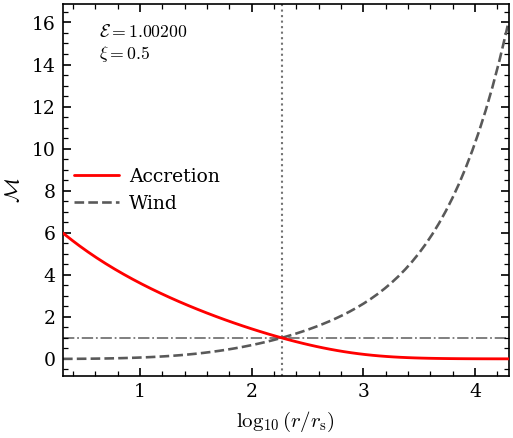

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import brentq


# ============================================================
# PUBLICATION-QUALITY MATPLOTLIB SETTINGS
# ============================================================

# LaTeX rendering is deliberately NOT required.
# mathtext with Computer Modern gives a journal-like appearance
# without requiring a local LaTeX installation.

plt.rcParams.update({

    # --------------------------------------------------------
    # Font
    # --------------------------------------------------------
    "font.family": "serif",
    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    # Mathematical text
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 0.8,

    # --------------------------------------------------------
    # Ticks
    # --------------------------------------------------------
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # --------------------------------------------------------
    # Lines
    # --------------------------------------------------------
    "lines.linewidth": 1.3,

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------
    "legend.fontsize": 9,
    "legend.frameon": False,
    "legend.handlelength": 2.5,
    "legend.handletextpad": 0.5,

    # --------------------------------------------------------
    # Saving
    # --------------------------------------------------------
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})


# ============================================================
# GLOBAL PARAMETERS
# ============================================================

xi = 0.5
eta = 1.0 / 1836.0

# -------------------- Input parameters ----------------------

E = 1.002

r_min = 2.05
r_max = 20000.0

# Initial guess for critical temperature
theta_guess = 0.09343

# Small displacement away from critical point
h = 1.0e-3


# ============================================================
# NUMERICAL PARAMETERS
# ============================================================

RTOL = 1.0e-9

ATOL = np.array([
    1.0e-11,      # u
    1.0e-11       # theta
])


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

output_dir = Path("solutions")
output_dir.mkdir(exist_ok=True)

figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)


# ============================================================
# THERMODYNAMIC FUNCTIONS
# ============================================================

def f_func(theta):

    theta = np.asarray(theta)

    return (
        (2.0 - xi)
        * (
            1.0
            + theta * (9.0 * theta + 3.0)
            / (3.0 * theta + 2.0)
        )
        +
        xi
        * (
            1.0 / eta
            +
            theta * (9.0 * theta + 3.0 / eta)
            / (3.0 * theta + 2.0 / eta)
        )
    )


def df_dtheta(theta):

    theta = np.asarray(theta)

    denom1 = 3.0 * theta + 2.0
    denom2 = 3.0 * theta + 2.0 / eta

    term1 = (
        9.0 * theta + 3.0
    ) / denom1

    term2 = (
        9.0 * theta
    ) / denom1**2

    term3 = (
        9.0 * theta + 3.0 / eta
    ) / denom2

    term4 = (
        9.0 * theta
    ) / (
        eta * denom2**2
    )

    return (
        (2.0 - xi)
        * (term1 + term2)
        +
        xi
        * (term3 + term4)
    )


def d2f_dtheta2(theta):

    theta = np.asarray(theta)

    eta_inv = 1.0 / eta

    denom1 = 3.0 * theta + 2.0
    denom2 = 3.0 * theta + 2.0 * eta_inv

    term1 = (
        18.0 / denom1**2
    )

    term2 = (
        54.0 * theta / denom1**3
    )

    term3 = (
        9.0 * (1.0 + eta_inv)
        / denom2**2
    )

    term4 = (
        54.0 * theta * eta_inv
        / denom2**3
    )

    return (
        (2.0 - xi)
        * (term1 - term2)
        +
        xi
        * (term3 - term4)
    )


def N_func(theta):

    return 0.5 * df_dtheta(theta)


def Gamma_func(theta):

    return 1.0 + 1.0 / N_func(theta)


def dGamma_dtheta(theta):

    N = N_func(theta)

    return (
        -d2f_dtheta2(theta)
        / (2.0 * N**2)
    )


def a_sq(theta):

    f = f_func(theta)
    Gamma = Gamma_func(theta)

    return (
        2.0 * Gamma * theta
        / (f + 2.0 * theta)
    )


# ============================================================
# SONIC / CRITICAL POINT
# ============================================================

def r_sonic(theta):

    f = f_func(theta)
    Gamma = Gamma_func(theta)

    term = (
        (f + 2.0 * theta)
        / (2.0 * Gamma * theta)
    )

    return 0.5 * (term + 3.0)


def E_sonic(theta):

    r = r_sonic(theta)
    a2 = a_sq(theta)

    numerator = (
        (f_func(theta) + 2.0 * theta)
        * np.sqrt(1.0 - 2.0 / r)
    )

    denominator = (
        np.sqrt(1.0 - a2)
        * (2.0 - xi + xi / eta)
    )

    return numerator / denominator - E


# ============================================================
# FIND ROOT BRACKET
# ============================================================

def find_root_bracket(
    func,
    x0,
    factor=1.5,
    max_iter=50
):

    x_left = x0 / factor
    x_right = x0 * factor

    for _ in range(max_iter):

        f_left = func(x_left)
        f_right = func(x_right)

        if (
            np.isfinite(f_left)
            and np.isfinite(f_right)
            and f_left * f_right < 0.0
        ):
            return x_left, x_right

        x_left /= factor
        x_right *= factor

    raise RuntimeError(
        "Could not find a sign-changing bracket "
        "for the critical point."
    )


# ============================================================
# CRITICAL TEMPERATURE
# ============================================================

theta_lo, theta_hi = find_root_bracket(
    E_sonic,
    theta_guess
)

theta_c = brentq(
    E_sonic,
    theta_lo,
    theta_hi,
    xtol=1.0e-12,
    rtol=1.0e-12
)


# ============================================================
# CRITICAL POINT QUANTITIES
# ============================================================

rc = r_sonic(theta_c)

a_c = np.sqrt(
    a_sq(theta_c)
)

u_c = a_c

Gamma_c = Gamma_func(theta_c)

N_c = N_func(theta_c)

dGamma_c = dGamma_dtheta(theta_c)


print()
print("=" * 65)
print("Critical point")
print("=" * 65)

print(f"theta_c       = {theta_c:.10e}")
print(f"r_c           = {rc:.10e}")
print(f"u_c           = {u_c:.10e}")
print(f"c_s,c         = {a_c:.10e}")
print(f"Gamma_c       = {Gamma_c:.10e}")
print(f"N_c           = {N_c:.10e}")
print(f"dGamma/dtheta = {dGamma_c:.10e}")


# ============================================================
# CRITICAL DERIVATIVE
# ============================================================

common = (
    (1.0 - N_c * a_c**2)
    +
    (theta_c / Gamma_c) * dGamma_c
)


A = (
    2.0
    +
    common
    / (
        N_c
        * (1.0 - a_c**2)
    )
) * rc * (rc - 2.0)


B = (
    2.0
    * common
    / (N_c * a_c)
)


C = (
    2.0
    * common
    / (N_c * rc)
    -
    2.0 * a_c**2
    * (1.0 - a_c**2)
)


discriminant = B**2 - 4.0 * A * C


if discriminant < 0.0:

    raise RuntimeError(
        "Critical-point quadratic has negative "
        f"discriminant: {discriminant:.6e}"
    )


sqrt_discriminant = np.sqrt(
    discriminant
)


dvdr_roots = np.array([
    (-B + sqrt_discriminant)
    / (2.0 * A),

    (-B - sqrt_discriminant)
    / (2.0 * A)
])


print()
print("Critical derivatives")
print("-" * 65)
print(
    f"dv/dr root 1 = "
    f"{dvdr_roots[0]:.10e}"
)

print(
    f"dv/dr root 2 = "
    f"{dvdr_roots[1]:.10e}"
)


# ============================================================
# dtheta/dr
# ============================================================

def dtheta_dr(
    r,
    u,
    theta,
    dudr
):

    N = N_func(theta)

    geometric_term = (
        (2.0 * r - 3.0)
        / (r * (r - 2.0))
    )

    velocity_term = (
        dudr
        / (u * (1.0 - u**2))
    )

    return (
        -theta / N
        * (
            geometric_term
            + velocity_term
        )
    )


# ============================================================
# ODE SYSTEM
# ============================================================

def rhs(r, y):

    u, theta = y

    a2 = a_sq(theta)
    N = N_func(theta)

    numerator = (
        (1.0 - u**2)
        * (
            a2 * (2.0 * r - 3.0)
            - 1.0
        )
    )

    denominator = (
        r
        * (r - 2.0)
        * (
            u - a2 / u
        )
    )

    dudr = (
        numerator
        / denominator
    )

    dthetadr = (
        -theta / N
        * (
            (2.0 * r - 3.0)
            / (r * (r - 2.0))
            +
            dudr
            / (u * (1.0 - u**2))
        )
    )

    return np.array([
        dudr,
        dthetadr
    ])


# ============================================================
# INWARD INTEGRATION
# ============================================================

solutions_in = []


for dudr_c in dvdr_roots:

    dtheta_c = dtheta_dr(
        rc,
        u_c,
        theta_c,
        dudr_c
    )

    u0 = (
        u_c
        - dudr_c * h
    )

    theta0 = (
        theta_c
        - dtheta_c * h
    )

    y0 = np.array([
        u0,
        theta0
    ])

    sol = solve_ivp(
        rhs,
        (rc - h, r_min),
        y0,
        method="DOP853",
        rtol=RTOL,
        atol=ATOL,
        dense_output=True
    )

    solutions_in.append(sol)


for i, sol in enumerate(
    solutions_in
):

    if not sol.success:

        raise RuntimeError(
            f"Inward integration "
            f"{i + 1} failed:\n"
            f"{sol.message}"
        )


# ============================================================
# IDENTIFY ACCRETION / WIND
# ============================================================

velocity_change = np.array([
    sol.y[0, -1]
    - sol.y[0, 0]
    for sol in solutions_in
])


acc_index = np.argmax(
    velocity_change
)

wind_index = 1 - acc_index


sol_acc_in = (
    solutions_in[acc_index]
)

sol_wind_in = (
    solutions_in[wind_index]
)


dvdr_acc = (
    dvdr_roots[acc_index]
)

dvdr_wind = (
    dvdr_roots[wind_index]
)


print()
print("=" * 65)
print("Branches")
print("=" * 65)

print(
    f"Accretion dv/dr = "
    f"{dvdr_acc:.10e}"
)

print(
    f"Wind dv/dr      = "
    f"{dvdr_wind:.10e}"
)


# ============================================================
# OUTWARD INITIAL CONDITIONS
# ============================================================

def outward_initial_condition(
    dudr_c
):

    dtheta_c = dtheta_dr(
        rc,
        u_c,
        theta_c,
        dudr_c
    )

    u0 = (
        u_c
        + dudr_c * h
    )

    theta0 = (
        theta_c
        + dtheta_c * h
    )

    return np.array([
        u0,
        theta0
    ])


y0_acc_out = (
    outward_initial_condition(
        dvdr_acc
    )
)


y0_wind_out = (
    outward_initial_condition(
        dvdr_wind
    )
)


# ============================================================
# SOLVER OPTIONS
# ============================================================

solver_options = {

    "method": "DOP853",

    "rtol": RTOL,

    "atol": ATOL,

    "dense_output": True
}


# ============================================================
# OUTWARD INTEGRATION
# ============================================================

sol_acc_out = solve_ivp(
    rhs,
    (rc + h, r_max),
    y0_acc_out,
    **solver_options
)


sol_wind_out = solve_ivp(
    rhs,
    (rc + h, r_max),
    y0_wind_out,
    **solver_options
)


if not sol_acc_out.success:

    raise RuntimeError(
        "Accretion outward integration failed:\n"
        + sol_acc_out.message
    )


if not sol_wind_out.success:

    raise RuntimeError(
        "Wind outward integration failed:\n"
        + sol_wind_out.message
    )


# ============================================================
# COMBINE INWARD + OUTWARD SOLUTIONS
# ============================================================

def combine_solutions(
    sol_in,
    sol_out
):

    r = np.concatenate([
        sol_in.t[::-1],
        sol_out.t
    ])

    y = np.concatenate([
        sol_in.y[:, ::-1],
        sol_out.y
    ], axis=1)

    return r, y


r_acc, y_acc = (
    combine_solutions(
        sol_acc_in,
        sol_acc_out
    )
)


r_wind, y_wind = (
    combine_solutions(
        sol_wind_in,
        sol_wind_out
    )
)


# ============================================================
# EXTRACT VARIABLES
# ============================================================

u_acc = y_acc[0]

theta_acc = y_acc[1]


u_wind = y_wind[0]

theta_wind = y_wind[1]


# ============================================================
# SOUND SPEED
# ============================================================

cs_acc = np.sqrt(
    a_sq(theta_acc)
)


cs_wind = np.sqrt(
    a_sq(theta_wind)
)


# ============================================================
# MACH NUMBER
# ============================================================

M_acc = (
    u_acc
    / cs_acc
)


M_wind = (
    u_wind
    / cs_wind
)


# ============================================================
# SAVE ACCRETION SOLUTION
# ============================================================

filename = (
    output_dir
    /
    (
        f"accretion"
        f"_E{E:.6f}"
        f"_xi{xi:.3f}"
        f".dat"
    )
)


data_acc = np.column_stack([
    r_acc,
    theta_acc,
    u_acc,
    cs_acc,
    M_acc
])


header = (
    f"E = {E:.12e}\n"
    f"xi = {xi:.12e}\n"
    f"theta_c = {theta_c:.12e}\n"
    f"r_c = {rc:.12e}\n"
    f"u_c = {u_c:.12e}\n"
    f"c_s,c = {a_c:.12e}\n"
    f"columns: r theta u c_s M"
)


np.savetxt(
    filename,
    data_acc,
    fmt="%.12e",
    delimiter="\t",
    header=header,
    comments="# "
)


print()
print("=" * 65)
print("Accretion solution saved")
print("=" * 65)

print(f"File: {filename}")
print(
    f"Number of data points: "
    f"{len(r_acc)}"
)


# ============================================================
# ADAPTIVE SAMPLING INFORMATION
# ============================================================

dr_acc = np.diff(r_acc)


print()
print("Adaptive radial sampling")
print("-" * 65)

print(
    f"Minimum |dr| = "
    f"{np.min(np.abs(dr_acc)):.6e}"
)

print(
    f"Maximum |dr| = "
    f"{np.max(np.abs(dr_acc)):.6e}"
)

print(
    f"Total points = "
    f"{len(r_acc)}"
)


# ============================================================
# PUBLICATION FIGURE
# ============================================================

# ------------------------------------------------------------
# Figure dimensions
#
# 3.4 inches is approximately a single-column width for many
# astrophysics journals.
#
# Change to (6.8, 4.8) for a two-column figure.
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(3.5, 3.0)
)


# ------------------------------------------------------------
# Accretion branch
# ------------------------------------------------------------

ax.plot(
    np.log10(r_acc),
    M_acc,

    color="red",
    linestyle="-",
    linewidth=1.35,

    label="Accretion",

    solid_capstyle="round",
    zorder=3
)


# ------------------------------------------------------------
# Wind branch
# ------------------------------------------------------------

ax.plot(
    np.log10(r_wind),
    M_wind,

    color="0.35",
    linestyle="--",
    linewidth=1.25,

    label="Wind",

    dash_capstyle="butt",
    zorder=2
)


# ------------------------------------------------------------
# Critical point
# ------------------------------------------------------------

ax.axvline(
    np.log10(rc),

    color="0.45",
    linestyle=":",
    linewidth=1.0,

    zorder=1
)


# ------------------------------------------------------------
# Sonic Mach number M = 1
# ------------------------------------------------------------

ax.axhline(
    1.0,

    color="0.45",
    linestyle="-.",
    linewidth=0.85,

    zorder=1
)


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$",
    fontsize=10
)

ax.set_ylabel(
    r"$\mathcal{M}$",
    fontsize=10
)


# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True,

    labelsize=9
)


ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)


# ============================================================
# MINOR TICKS
# ============================================================

ax.minorticks_on()


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    np.log10(r_min),
    np.log10(r_max)
)


# Do not hard-code the upper y limit too aggressively.
# Determine it from the actual data.

M_all = np.concatenate([
    M_acc[np.isfinite(M_acc)],
    M_wind[np.isfinite(M_wind)]
])

M_min = np.min(M_all)
M_max = np.max(M_all)

margin = 0.05 * (
    M_max - M_min
)

ax.set_ylim(
    M_min - margin,
    M_max + margin
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="best",
    frameon=False,
    handlelength=2.4,
    handletextpad=0.5,
    borderaxespad=0.2
)


# ============================================================
# OPTIONAL PARAMETER ANNOTATION
# ============================================================

# For a journal figure, I recommend keeping the annotation
# minimal. It is better to put most model information in the
# caption.

ax.text(
    0.08,
    0.95,

    (
        fr"$\mathcal{{E}}={E:.5f}$"
        "\n"
        fr"$\xi={xi:g}$"
    ),

    transform=ax.transAxes,

    fontsize=8.5,

    verticalalignment="top",
    horizontalalignment="left"
)


# ============================================================
# SPINES
# ============================================================

for spine in ax.spines.values():
    spine.set_linewidth(0.8)


# ============================================================
# LAYOUT
# ============================================================

fig.tight_layout(
    pad=0.5
)


# ============================================================
# SAVE FIGURE
# ============================================================

figure_base = (
    figure_dir
    /
    (
        f"mach"
        f"_E{E:.6f}"
        f"_xi{xi:.3f}"
    )
)


# ------------------------------------------------------------
# Vector PDF -- primary journal output
# ------------------------------------------------------------

fig.savefig(
    figure_base.with_suffix(".pdf"),
    format="pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03
)


# ------------------------------------------------------------
# High-resolution PNG -- convenient preview
# ------------------------------------------------------------

fig.savefig(
    figure_base.with_suffix(".png"),
    format="png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03
)


print()
print("=" * 65)
print("Publication figures saved")
print("=" * 65)

print(
    f"PDF : "
    f"{figure_base.with_suffix('.pdf')}"
)

print(
    f"PNG : "
    f"{figure_base.with_suffix('.png')}"
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()

### Regenerating the accretion branch from the saved data.


Accretion profile loaded from saved data
Input file : solutions/accretion_E1.000020_xi1.000.dat
E          : 1.000020000000e+00
xi         : 1.000000000000e+00
theta_c    : 9.343073036486e-02
r_c        : 3.078918856268e+03
u_c        : 1.274652191272e-02
c_s,c      : 1.274652191272e-02
Data points: 89

Figures:
PDF : figures/mach_E1.000020_xi1.pdf
PNG : figures/mach_E1.000020_xi1.png


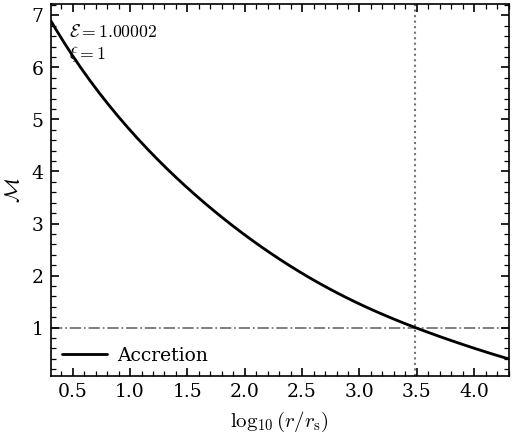

In [8]:
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# Publication-quality Matplotlib settings
# ============================================================

plt.rcParams.update({

    # --------------------------------------------------------
    # Fonts
    # --------------------------------------------------------
    "font.family": "serif",
    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 0.8,

    # --------------------------------------------------------
    # Tick labels
    # --------------------------------------------------------
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    # --------------------------------------------------------
    # Tick direction
    # --------------------------------------------------------
    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    # --------------------------------------------------------
    # Major ticks
    # --------------------------------------------------------
    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --------------------------------------------------------
    # Minor ticks
    # --------------------------------------------------------
    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # --------------------------------------------------------
    # Lines
    # --------------------------------------------------------
    "lines.linewidth": 1.35,

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------
    "legend.fontsize": 9,
    "legend.frameon": False,
    "legend.handlelength": 2.4,
    "legend.handletextpad": 0.5,
})


# ============================================================
# Input data file
# ============================================================

filename = Path(
    "solutions/accretion_E1.000020_xi1.000.dat"
)


# ============================================================
# Function to read metadata from .dat header
# ============================================================

def read_metadata(filename):
    """
    Read model parameters stored in the header of the .dat file.

    Expected header entries:

        E = ...
        xi = ...
        theta_c = ...
        r_c = ...
        u_c = ...
        c_s,c = ...

    Returns
    -------
    metadata : dict
        Dictionary containing the available parameters.
    """

    metadata = {}

    with open(filename, "r") as file:

        for line in file:

            if not line.startswith("#"):
                continue

            # Remove the comment character
            line = line[1:].strip()

            # ------------------------------------------------
            # Match:
            #
            # E = 1.000020000000e+00
            # ------------------------------------------------
            match = re.match(
                r"^E\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["E"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # xi
            # ------------------------------------------------
            match = re.match(
                r"^xi\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["xi"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # theta_c
            # ------------------------------------------------
            match = re.match(
                r"^theta_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["theta_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # r_c
            # ------------------------------------------------
            match = re.match(
                r"^r_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["r_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # u_c
            # ------------------------------------------------
            match = re.match(
                r"^u_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["u_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # c_s,c
            # ------------------------------------------------
            match = re.match(
                r"^c_s,c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["c_s_c"] = float(
                    match.group(1)
                )

    return metadata


# ============================================================
# Read metadata
# ============================================================

metadata = read_metadata(filename)


# ------------------------------------------------------------
# Check required metadata
# ------------------------------------------------------------

required_parameters = [
    "E",
    "xi",
    "r_c"
]

missing = [
    key
    for key in required_parameters
    if key not in metadata
]

if missing:

    raise RuntimeError(
        "The following required parameters were not "
        "found in the .dat header: "
        + ", ".join(missing)
    )


E = metadata["E"]
xi = metadata["xi"]
rc = metadata["r_c"]


# ============================================================
# Load numerical data
# ============================================================

data = np.loadtxt(
    filename,
    comments="#"
)


# ------------------------------------------------------------
# Columns:
#
# 0 = r
# 1 = theta
# 2 = u
# 3 = c_s
# 4 = M
# ------------------------------------------------------------

r = data[:, 0]

theta = data[:, 1]

u = data[:, 2]

cs = data[:, 3]

M = data[:, 4]


# ============================================================
# Basic validation
# ============================================================

if data.shape[1] < 5:

    raise RuntimeError(
        "The data file must contain at least "
        "five columns: r, theta, u, c_s, M."
    )


if not np.all(np.isfinite(r)):

    raise RuntimeError(
        "The radial coordinate contains non-finite values."
    )


if not np.all(np.isfinite(M)):

    raise RuntimeError(
        "The Mach number contains non-finite values."
    )


# ============================================================
# Publication figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(3.5, 3.0)
)


# ============================================================
# Accretion curve
# ============================================================

ax.plot(
    np.log10(r),
    M,

    color="black",
    linestyle="-",
    linewidth=1.35,

    label="Accretion",

    solid_capstyle="round",

    zorder=3
)


# ============================================================
# Critical point
# ============================================================

ax.axvline(
    np.log10(rc),

    color="0.45",
    linestyle=":",
    linewidth=1.0,

    zorder=1
)


# ============================================================
# Sonic condition M = 1
# ============================================================

ax.axhline(
    1.0,

    color="0.45",
    linestyle="-.",
    linewidth=0.85,

    zorder=1
)


# ============================================================
# Axis labels
# ============================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$",
    fontsize=10
)

ax.set_ylabel(
    r"$\mathcal{M}$",
    fontsize=10
)


# ============================================================
# Major ticks
# ============================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True,

    labelsize=9
)


# ============================================================
# Minor ticks
# ============================================================

ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)

ax.minorticks_on()


# ============================================================
# Axis limits
# ============================================================

x = np.log10(r)

x_min = np.min(x)
x_max = np.max(x)

ax.set_xlim(
    x_min,
    x_max
)


# ------------------------------------------------------------
# Determine sensible y limits automatically
# ------------------------------------------------------------

M_valid = M[np.isfinite(M)]

M_min = np.min(M_valid)
M_max = np.max(M_valid)

if M_max > M_min:

    margin = 0.05 * (
        M_max - M_min
    )

else:

    margin = 0.1 * max(
        abs(M_max),
        1.0
    )


ax.set_ylim(
    M_min - margin,
    M_max + margin
)


# ============================================================
# Legend
# ============================================================

ax.legend(
    loc="best",
    frameon=False,

    handlelength=2.4,
    handletextpad=0.5,

    borderaxespad=0.2
)


# ============================================================
# Parameter annotation
# ============================================================

ax.text(
    0.04,
    0.95,

    (
        fr"$\mathcal{{E}}={E:.5f}$"
        "\n"
        fr"$\xi={xi:g}$"
    ),

    transform=ax.transAxes,

    fontsize=8.5,

    verticalalignment="top",
    horizontalalignment="left"
)


# ============================================================
# Spines
# ============================================================

for spine in ax.spines.values():

    spine.set_linewidth(0.8)


# ============================================================
# Layout
# ============================================================

fig.tight_layout(
    pad=0.5
)


# ============================================================
# Output filename
# ============================================================

figure_dir = Path("figures")

figure_dir.mkdir(
    exist_ok=True
)


figure_base = (
    figure_dir
    /
    (
        "mach"
        f"_E{E:.6f}"
        f"_xi{xi:.3f}"
        "_from_data"
    )
)


# ============================================================
# Save PDF
# ============================================================

pdf_file = figure_base.with_suffix(
    ".pdf"
)

fig.savefig(
    pdf_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ============================================================
# Save PNG
# ============================================================

png_file = figure_base.with_suffix(
    ".png"
)

fig.savefig(
    png_file,

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ============================================================
# Print information
# ============================================================

print()
print("=" * 65)
print("Accretion profile loaded from saved data")
print("=" * 65)

print(f"Input file : {filename}")
print(f"E          : {E:.12e}")
print(f"xi         : {xi:.12e}")
print(f"theta_c    : {metadata['theta_c']:.12e}")
print(f"r_c        : {rc:.12e}")

if "u_c" in metadata:
    print(
        f"u_c        : "
        f"{metadata['u_c']:.12e}"
    )

if "c_s_c" in metadata:
    print(
        f"c_s,c      : "
        f"{metadata['c_s_c']:.12e}"
    )

print(f"Data points: {len(r)}")

print()
print("Figures:")
print(f"PDF : {pdf_file}")
print(f"PNG : {png_file}")

print("=" * 65)


# ============================================================
# Display
# ============================================================

plt.show()

### Various other quantitites related to acretion and their distribution in stead-state (stationary)

Saved: figures/profiles_E1.000020_xi1.000_u.pdf
Saved: figures/profiles_E1.000020_xi1.000_u.png
Saved: figures/profiles_E1.000020_xi1.000_cs.pdf
Saved: figures/profiles_E1.000020_xi1.000_cs.png
Saved: figures/profiles_E1.000020_xi1.000_theta.pdf
Saved: figures/profiles_E1.000020_xi1.000_theta.png
Saved: figures/profiles_E1.000020_xi1.000_Gamma.pdf
Saved: figures/profiles_E1.000020_xi1.000_Gamma.png


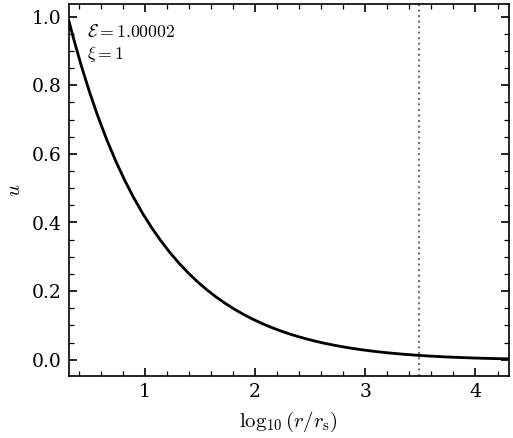

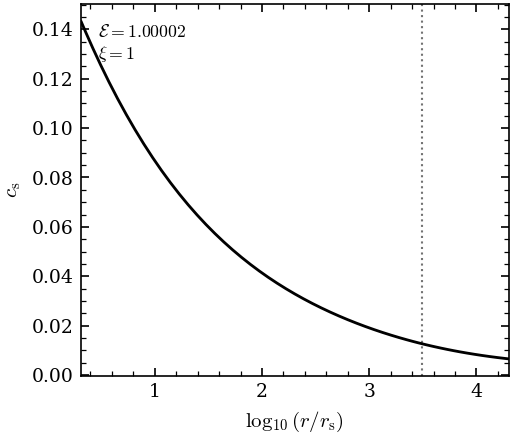

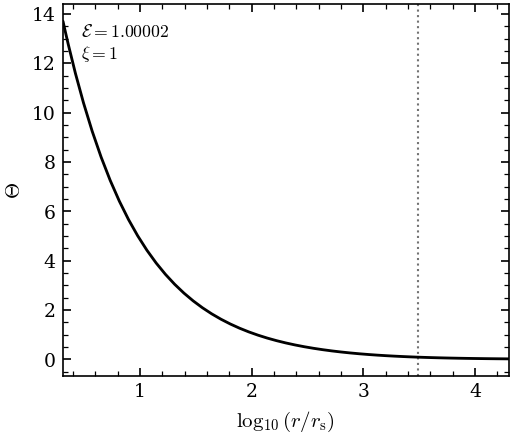

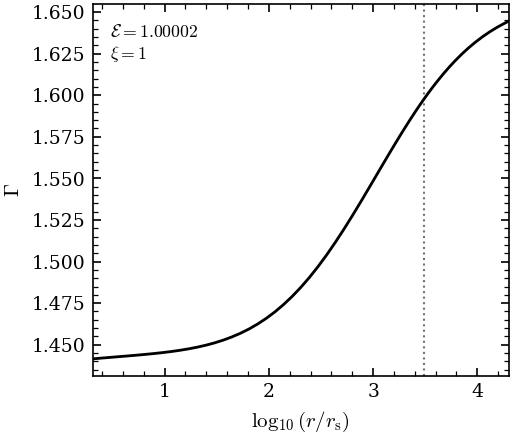


Accretion profiles
Input file : solutions/accretion_E1.000020_xi1.000.dat
E          : 1.000020000000e+00
xi         : 1.000000000000e+00
theta_c    : 9.343073036486e-02
r_c        : 3.078918856268e+03

Number of points:
89

Gamma range:
1.44151973e+00 to 1.64447893e+00


In [9]:
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# Publication-quality Matplotlib settings
# ============================================================

plt.rcParams.update({

    # --------------------------------------------------------
    # Fonts
    # --------------------------------------------------------
    "font.family": "serif",
    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 0.8,

    # --------------------------------------------------------
    # Tick labels
    # --------------------------------------------------------
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    # --------------------------------------------------------
    # Tick direction
    # --------------------------------------------------------
    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    # --------------------------------------------------------
    # Major ticks
    # --------------------------------------------------------
    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --------------------------------------------------------
    # Minor ticks
    # --------------------------------------------------------
    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # --------------------------------------------------------
    # Lines
    # --------------------------------------------------------
    "lines.linewidth": 1.35,

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------
    "legend.fontsize": 9,
    "legend.frameon": False,
    "legend.handlelength": 2.4,
    "legend.handletextpad": 0.5,
})


# ============================================================
# Input data file
# ============================================================

filename = Path(
    "solutions/accretion_E1.000020_xi1.000.dat"
)


# ============================================================
# Fixed EOS parameter
# ============================================================

eta = 1.0 / 1836.0


# ============================================================
# Read metadata from .dat header
# ============================================================

def read_metadata(filename):

    metadata = {}

    with open(filename, "r") as file:

        for line in file:

            if not line.startswith("#"):
                continue

            line = line[1:].strip()

            # ------------------------------------------------
            # E
            # ------------------------------------------------
            match = re.match(
                r"^E\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["E"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # xi
            # ------------------------------------------------
            match = re.match(
                r"^xi\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["xi"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # theta_c
            # ------------------------------------------------
            match = re.match(
                r"^theta_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["theta_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # r_c
            # ------------------------------------------------
            match = re.match(
                r"^r_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["r_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # u_c
            # ------------------------------------------------
            match = re.match(
                r"^u_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["u_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # c_s,c
            # ------------------------------------------------
            match = re.match(
                r"^c_s,c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:
                metadata["c_s_c"] = float(
                    match.group(1)
                )

    return metadata


# ============================================================
# Read metadata
# ============================================================

metadata = read_metadata(filename)


required_parameters = [
    "E",
    "xi",
    "theta_c",
    "r_c"
]


missing = [
    key
    for key in required_parameters
    if key not in metadata
]


if missing:

    raise RuntimeError(
        "Missing parameters in .dat header: "
        + ", ".join(missing)
    )


E = metadata["E"]

xi = metadata["xi"]

theta_c = metadata["theta_c"]

rc = metadata["r_c"]


# ============================================================
# Load data
# ============================================================

data = np.loadtxt(
    filename,
    comments="#"
)


if data.ndim != 2 or data.shape[1] < 5:

    raise RuntimeError(
        "Expected at least five columns:\n"
        "r, theta, u, c_s, M"
    )


# ============================================================
# Extract columns
# ============================================================

r = data[:, 0]

theta = data[:, 1]

u = data[:, 2]

cs = data[:, 3]

M = data[:, 4]


# ============================================================
# EOS functions
# ============================================================

def df_dtheta(theta):

    theta = np.asarray(theta)

    denom1 = (
        3.0 * theta + 2.0
    )

    denom2 = (
        3.0 * theta
        + 2.0 / eta
    )

    term1 = (
        9.0 * theta + 3.0
    ) / denom1

    term2 = (
        9.0 * theta
    ) / denom1**2

    term3 = (
        9.0 * theta + 3.0 / eta
    ) / denom2

    term4 = (
        9.0 * theta
    ) / (
        eta * denom2**2
    )

    return (
        (2.0 - xi)
        * (term1 + term2)
        +
        xi
        * (term3 + term4)
    )


def N_func(theta):

    return 0.5 * df_dtheta(theta)


def Gamma_func(theta):

    return (
        1.0
        + 1.0 / N_func(theta)
    )


# ============================================================
# Calculate Gamma from saved theta
# ============================================================

Gamma = Gamma_func(theta)


# ============================================================
# Common x-axis
# ============================================================

x = np.log10(r)


# ============================================================
# Output directory
# ============================================================

figure_dir = Path("figures")

figure_dir.mkdir(
    exist_ok=True
)


figure_prefix = (
    figure_dir
    /
    (
        f"profiles"
        f"_E{E:.6f}"
        f"_xi{xi:.3f}"
    )
)


# ============================================================
# Common plotting function
# ============================================================

def make_profile_plot(
    y,
    ylabel,
    filename,
    label=None,
    yscale="linear"
):

    fig, ax = plt.subplots(
        figsize=(3.5, 3.0)
    )

    # --------------------------------------------------------
    # Main curve
    # --------------------------------------------------------

    ax.plot(
        x,
        y,

        color="black",
        linestyle="-",
        linewidth=1.35,

        solid_capstyle="round",

        label=label,

        zorder=3
    )

    # --------------------------------------------------------
    # Critical point
    # --------------------------------------------------------

    ax.axvline(
        np.log10(rc),

        color="0.45",
        linestyle=":",
        linewidth=1.0,

        zorder=1
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel(
        r"$\log_{10}(r/r_{\rm s})$",
        fontsize=10
    )

    ax.set_ylabel(
        ylabel,
        fontsize=10
    )

    # --------------------------------------------------------
    # Scale
    # --------------------------------------------------------

    ax.set_yscale(
        yscale
    )

    # --------------------------------------------------------
    # Ticks
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        which="major",

        direction="in",

        length=4.0,
        width=0.8,

        top=True,
        right=True,

        labelsize=9
    )

    ax.tick_params(
        axis="both",
        which="minor",

        direction="in",

        length=2.5,
        width=0.6,

        top=True,
        right=True
    )

    ax.minorticks_on()

    # --------------------------------------------------------
    # x limits
    # --------------------------------------------------------

    ax.set_xlim(
        x.min(),
        x.max()
    )

    # --------------------------------------------------------
    # y limits
    # --------------------------------------------------------

    finite_y = y[
        np.isfinite(y)
    ]

    y_min = finite_y.min()
    y_max = finite_y.max()

    if y_max > y_min:

        margin = (
            0.05
            * (y_max - y_min)
        )

        ax.set_ylim(
            y_min - margin,
            y_max + margin
        )

    # --------------------------------------------------------
    # Parameters
    # --------------------------------------------------------

    ax.text(
        0.04,
        0.95,

        (
            fr"$\mathcal{{E}}={E:.5f}$"
            "\n"
            fr"$\xi={xi:g}$"
        ),

        transform=ax.transAxes,

        fontsize=8.5,

        verticalalignment="top",
        horizontalalignment="left"
    )

    # --------------------------------------------------------
    # Spines
    # --------------------------------------------------------

    for spine in ax.spines.values():

        spine.set_linewidth(0.8)

    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    fig.tight_layout(
        pad=0.5
    )

    # --------------------------------------------------------
    # Save PDF
    # --------------------------------------------------------

    pdf_file = Path(
        str(filename) + ".pdf"
    )

    fig.savefig(
        pdf_file,

        format="pdf",

        dpi=600,

        bbox_inches="tight",

        pad_inches=0.03
    )

    # --------------------------------------------------------
    # Save PNG
    # --------------------------------------------------------

    png_file = Path(
        str(filename) + ".png"
    )

    fig.savefig(
        png_file,

        format="png",

        dpi=600,

        bbox_inches="tight",

        pad_inches=0.03
    )

    print(
        f"Saved: {pdf_file}"
    )

    print(
        f"Saved: {png_file}"
    )

    return fig, ax


# ============================================================
# 1. Radial velocity u
# ============================================================

fig_u, ax_u = make_profile_plot(

    y=u,

    ylabel=r"$u$",

    filename=(
        str(figure_prefix)
        + "_u"
    ),

    label=r"$u$"
)


# ============================================================
# 2. Sound speed c_s
# ============================================================

fig_cs, ax_cs = make_profile_plot(

    y=cs,

    ylabel=r"$c_{\rm s}$",

    filename=(
        str(figure_prefix)
        + "_cs"
    ),

    label=r"$c_{\rm s}$"
)


# ============================================================
# 3. Temperature theta
# ============================================================

fig_theta, ax_theta = make_profile_plot(

    y=theta,

    ylabel=r"$\Theta$",

    filename=(
        str(figure_prefix)
        + "_theta"
    ),

    label=r"$\Theta$"
)


# ============================================================
# 4. Adiabatic index Gamma
# ============================================================

fig_gamma, ax_gamma = make_profile_plot(

    y=Gamma,

    ylabel=r"$\Gamma$",

    filename=(
        str(figure_prefix)
        + "_Gamma"
    ),

    label=r"$\Gamma$"
)


# ============================================================
# Display
# ============================================================

plt.show()


# ============================================================
# Print useful information
# ============================================================

print()
print("=" * 65)
print("Accretion profiles")
print("=" * 65)

print(f"Input file : {filename}")
print(f"E          : {E:.12e}")
print(f"xi         : {xi:.12e}")
print(f"theta_c    : {theta_c:.12e}")
print(f"r_c        : {rc:.12e}")

print()
print("Number of points:")
print(f"{len(r)}")

print()
print("Gamma range:")
print(
    f"{Gamma.min():.8e} "
    f"to "
    f"{Gamma.max():.8e}"
)

print("=" * 65)


Physical density profile

Input solution:
    solutions/accretion_E1.000020_xi1.000.dat

Black-hole parameters:
    M_BH = 6.500e+09 M_sun
    M_BH = 1.292506e+43 g
    r_s  = 1.919671e+15 cm
    r_s  = 128.322054 AU

Accretion rates:
    0.1 M_sun/yr = 6.301081e+24 g/s
    0.2 M_sun/yr = 1.260216e+25 g/s

Hydrodynamic parameters:
    E  = 1.000020000000e+00
    xi = 1.000000000000e+00
    r_c = 3.078918856268e+03

Density ranges:
    Mdot = 0.1 M_sun/yr:
        rho_min = 4.314142e-24 g/cm^3
        rho_max = 1.094764e-18 g/cm^3
    Mdot = 0.2 M_sun/yr:
        rho_min = 8.628283e-24 g/cm^3
        rho_max = 2.189528e-18 g/cm^3

Figures:
    PDF: figures/density_E1.000020_xi1.000_MBH6.pdf
    PNG: figures/density_E1.000020_xi1.000_MBH6.png


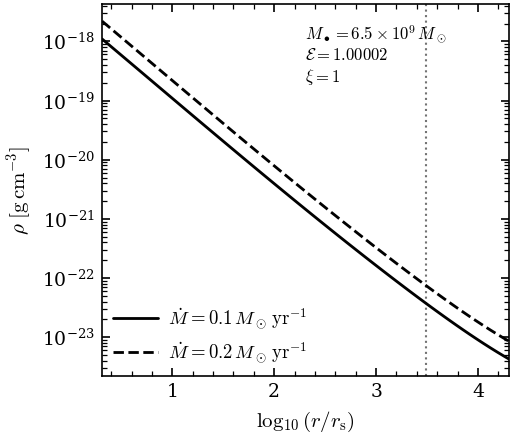

In [14]:
"""
===============================================================
Density profile from a saved accretion solution
===============================================================

This script reads a previously saved accretion solution:

    r, theta, u, c_s, M

and calculates the physical mass density using the steady
spherical mass-continuity relation

        Mdot = 4 pi R^2 rho u_phys

where

        R      = r * r_s
        r_s    = 2 G M_BH / c^2
        u_phys = u * c

Therefore,

        rho(r) = Mdot / [4 pi (r r_s)^2 u c]

The present hydrodynamical code uses u = v as the dimensionless
radial three-velocity.

---------------------------------------------------------------
Physical parameters used
---------------------------------------------------------------

Black-hole mass:

        M_BH = 6.5 x 10^9 M_sun

This is the central value reported by the Event Horizon Telescope
Collaboration for the mass of the M87 central black hole:

    Event Horizon Telescope Collaboration,
    "First M87 Event Horizon Telescope Results. VI.
     The Shadow and Mass of the Central Black Hole",
    The Astrophysical Journal Letters, 875, L6 (2019),
    DOI: 10.3847/2041-8213/ab1141

The EHT result is

        M_BH = (6.5 +/- 0.7) x 10^9 M_sun.

This script uses the central value 6.5 x 10^9 M_sun.

---------------------------------------------------------------
Accretion rates
---------------------------------------------------------------

The density profiles are calculated for

        Mdot = 0.1 M_sun yr^-1
        Mdot = 0.2 M_sun yr^-1

which correspond approximately to

        6.30 x 10^24 g s^-1
        1.26 x 10^25 g s^-1

respectively.

---------------------------------------------------------------
Important convention
---------------------------------------------------------------

The saved variable u is assumed to be the same velocity variable
called v in the original hydrodynamical code, i.e. a dimensionless
radial three-velocity.

If u instead represents a relativistic four-velocity u^r, the
mass-flux relation must be modified.

===============================================================
"""

# ============================================================
# Imports
# ============================================================

import re

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# Publication-quality Matplotlib settings
# ============================================================

plt.rcParams.update({

    # --------------------------------------------------------
    # Fonts
    # --------------------------------------------------------
    "font.family": "serif",

    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 0.8,

    # --------------------------------------------------------
    # Tick labels
    # --------------------------------------------------------
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    # --------------------------------------------------------
    # Tick direction
    # --------------------------------------------------------
    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    # --------------------------------------------------------
    # Major ticks
    # --------------------------------------------------------
    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --------------------------------------------------------
    # Minor ticks
    # --------------------------------------------------------
    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # --------------------------------------------------------
    # Lines
    # --------------------------------------------------------
    "lines.linewidth": 1.35,

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------
    "legend.fontsize": 9,
    "legend.frameon": False,

    "legend.handlelength": 2.4,
    "legend.handletextpad": 0.5,
})


# ============================================================
# Input solution
# ============================================================

filename = Path(
    "solutions/accretion_E1.000020_xi1.000.dat"
)


# ============================================================
# Physical constants -- CGS
# ============================================================

G = 6.67430e-8
# cm^3 g^-1 s^-2

c = 2.99792458e10
# cm s^-1

M_sun = 1.98847e33
# g

year = 365.25 * 24.0 * 3600.0
# s


# ============================================================
# Black-hole mass
# ============================================================

M_BH_solar = 6.5e9

M_BH = M_BH_solar * M_sun


# ============================================================
# Accretion rates
#
# Values requested:
#
#     0.1 and 0.2 M_sun yr^-1
# ============================================================

Mdot_solar_per_year = np.array([
    0.1,
    0.2
])


Mdot_cgs = (
    Mdot_solar_per_year
    * M_sun
    / year
)


# ============================================================
# Schwarzschild radius
# ============================================================

r_s = (
    2.0
    * G
    * M_BH
    / c**2
)


# ============================================================
# Read metadata from saved .dat file
# ============================================================

def read_metadata(filename):

    metadata = {}

    with open(filename, "r") as file:

        for line in file:

            if not line.startswith("#"):
                continue

            line = line[1:].strip()

            # ------------------------------------------------
            # E
            # ------------------------------------------------

            match = re.match(
                r"^E\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["E"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # xi
            # ------------------------------------------------

            match = re.match(
                r"^xi\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["xi"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # theta_c
            # ------------------------------------------------

            match = re.match(
                r"^theta_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["theta_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # r_c
            # ------------------------------------------------

            match = re.match(
                r"^r_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["r_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # u_c
            # ------------------------------------------------

            match = re.match(
                r"^u_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["u_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # c_s,c
            # ------------------------------------------------

            match = re.match(
                r"^c_s,c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["c_s_c"] = float(
                    match.group(1)
                )

    return metadata


# ============================================================
# Read metadata
# ============================================================

metadata = read_metadata(filename)


# ============================================================
# Check metadata
# ============================================================

required_parameters = [
    "E",
    "xi",
    "r_c"
]


missing = [
    key
    for key in required_parameters
    if key not in metadata
]


if missing:

    raise RuntimeError(
        "The following parameters were not found "
        "in the .dat header:\n"
        + ", ".join(missing)
    )


E = metadata["E"]

xi = metadata["xi"]

rc = metadata["r_c"]


# ============================================================
# Load saved solution
# ============================================================

data = np.loadtxt(
    filename,
    comments="#"
)


# ============================================================
# Validate data
# ============================================================

if data.ndim != 2:

    raise RuntimeError(
        "The data file does not contain a 2D array."
    )


if data.shape[1] < 5:

    raise RuntimeError(
        "Expected at least five columns:\n"
        "r, theta, u, c_s, M"
    )


# ============================================================
# Extract saved quantities
# ============================================================

r = data[:, 0]

theta = data[:, 1]

u = data[:, 2]

cs = data[:, 3]

Mach = data[:, 4]


# ============================================================
# Check physical validity
# ============================================================

if np.any(r <= 0):

    raise RuntimeError(
        "The radial coordinate contains "
        "non-positive values."
    )


if np.any(u <= 0):

    raise RuntimeError(
        "The saved velocity contains "
        "non-positive values."
    )


# ============================================================
# Physical radius
#
# R = r * r_s
# ============================================================

R = r * r_s


# ============================================================
# Physical radial velocity
#
# u_phys = u * c
# ============================================================

u_phys = u * c


# ============================================================
# Calculate density
#
# rho = Mdot / (4 pi R^2 u_phys)
# ============================================================

rho = (
    Mdot_cgs[:, None]
    /
    (
        4.0
        * np.pi
        * R[None, :]**2
        * u_phys[None, :]
    )
)


# ============================================================
# rho has shape:
#
#     [number of accretion rates, number of radial points]
#
# Therefore:
#
#     rho[0] -> 0.1 M_sun / yr
#     rho[1] -> 0.2 M_sun / yr
# ============================================================


# ============================================================
# Dimensionless x-coordinate
# ============================================================

x = np.log10(r)


# ============================================================
# Output directory
# ============================================================

figure_dir = Path(
    "figures"
)

figure_dir.mkdir(
    exist_ok=True
)


# ============================================================
# Output filename
# ============================================================

figure_base = (
    figure_dir
    /
    (
        f"density"
        f"_E{E:.6f}"
        f"_xi{xi:.3f}"
        f"_MBH{M_BH_solar:.2e}Msun"
    )
)


# ============================================================
# Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(3.5, 3.0)
)


# ============================================================
# Plot density profiles
# ============================================================

ax.plot(
    x,
    rho[0],

    color="black",
    linestyle="-",
    linewidth=1.35,

    label=(
        r"$\dot M=0.1\,M_\odot\,{\rm yr}^{-1}$"
    ),

    solid_capstyle="round",

    zorder=3
)


ax.plot(
    x,
    rho[1],

    color="black",
    linestyle="--",
    linewidth=1.35,

    label=(
        r"$\dot M=0.2\,M_\odot\,{\rm yr}^{-1}$"
    ),

    solid_capstyle="round",

    zorder=3
)


# ============================================================
# Critical radius
# ============================================================

ax.axvline(
    np.log10(rc),

    color="0.45",

    linestyle=":",

    linewidth=1.0,

    zorder=1
)


# ============================================================
# Logarithmic density axis
# ============================================================

ax.set_yscale(
    "log"
)


# ============================================================
# Labels
# ============================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$",
    fontsize=10
)


ax.set_ylabel(
    r"$\rho\ [{\rm g\,cm^{-3}}]$",
    fontsize=10
)


# ============================================================
# Ticks
# ============================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True,

    labelsize=9
)


ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)


ax.minorticks_on()


# ============================================================
# X limits
# ============================================================

ax.set_xlim(
    x.min(),
    x.max()
)


# ============================================================
# Parameter annotation
# ============================================================

ax.text(
    0.5,
    0.95,

    (
        fr"$M_\bullet={M_BH_solar/1e9:.1f}"
        r"\times10^9\,M_\odot$"
        "\n"
        fr"$\mathcal{{E}}={E:.5f}$"
        "\n"
        fr"$\xi={xi:g}$"
    ),

    transform=ax.transAxes,

    fontsize=8.0,

    verticalalignment="top",
    horizontalalignment="left"
)


# ============================================================
# Legend
# ============================================================

ax.legend(
    loc="best",

    frameon=False,

    handlelength=2.4,

    handletextpad=0.5,

    borderaxespad=0.2
)


# ============================================================
# Spines
# ============================================================

for spine in ax.spines.values():

    spine.set_linewidth(
        0.8
    )


# ============================================================
# Layout
# ============================================================

fig.tight_layout(
    pad=0.5
)


# ============================================================
# Save PDF
# ============================================================

pdf_file = figure_base.with_suffix(
    ".pdf"
)


fig.savefig(
    pdf_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ============================================================
# Save PNG
# ============================================================

png_file = figure_base.with_suffix(
    ".png"
)


fig.savefig(
    png_file,

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ============================================================
# Print physical quantities
# ============================================================

print()
print("=" * 70)
print("Physical density profile")
print("=" * 70)

print()
print("Input solution:")
print(
    f"    {filename}"
)

print()
print("Black-hole parameters:")
print(
    f"    M_BH = {M_BH_solar:.3e} M_sun"
)

print(
    f"    M_BH = {M_BH:.6e} g"
)

print(
    f"    r_s  = {r_s:.6e} cm"
)

print(
    f"    r_s  = {r_s / 1.495978707e13:.6f} AU"
)

print()
print("Accretion rates:")

for mdot_solar, mdot_cgs_value in zip(
    Mdot_solar_per_year,
    Mdot_cgs
):

    print(
        f"    {mdot_solar:.1f} M_sun/yr"
        f" = {mdot_cgs_value:.6e} g/s"
    )


print()
print("Hydrodynamic parameters:")
print(
    f"    E  = {E:.12e}"
)

print(
    f"    xi = {xi:.12e}"
)

print(
    f"    r_c = {rc:.12e}"
)

print()
print("Density ranges:")

for i, mdot_solar in enumerate(
    Mdot_solar_per_year
):

    print(
        f"    Mdot = {mdot_solar:.1f} M_sun/yr:"
    )

    print(
        f"        rho_min = "
        f"{rho[i].min():.6e} g/cm^3"
    )

    print(
        f"        rho_max = "
        f"{rho[i].max():.6e} g/cm^3"
    )


print()
print("Figures:")
print(
    f"    PDF: {pdf_file}"
)

print(
    f"    PNG: {png_file}"
)

print("=" * 70)


# ============================================================
# Display
# ============================================================

plt.show()


M87 ACCRETION-FLOW THERMODYNAMIC DIAGNOSTICS

Solution file:
    solutions/accretion_E1.000020_xi1.000.dat

M_BH = 6.500e+09 M_sun
r_s  = 1.919671e+15 cm
r_s  = 128.322 AU

E  = 1.00002000e+00
xi = 1.00000000e+00
r_c = 3.07891886e+03

kappa_es = 0.397726 cm^2 g^-1

Temperature conversion:
    T = Theta m_e c^2 / k_B
    m_e c^2/k_B = 5.929897e+09 K

Accretion rates used for optical depth:
    0.1 M_sun/yr = 6.301081e+24 g/s
    0.2 M_sun/yr = 1.260216e+25 g/s

Optical depth at the inner boundary:
    Mdot = 0.1: tau_es(r_min) = 3.876837e-03
    Mdot = 0.2: tau_es(r_min) = 7.753675e-03

Infall timescale:
    minimum = 4.216509e-03 yr
    maximum = 1.542962e+04 yr

Figures written to:
    figures/physical_temperature.pdf
    figures/electron_scattering_optical_depth.pdf
    figures/infall_timescale.pdf



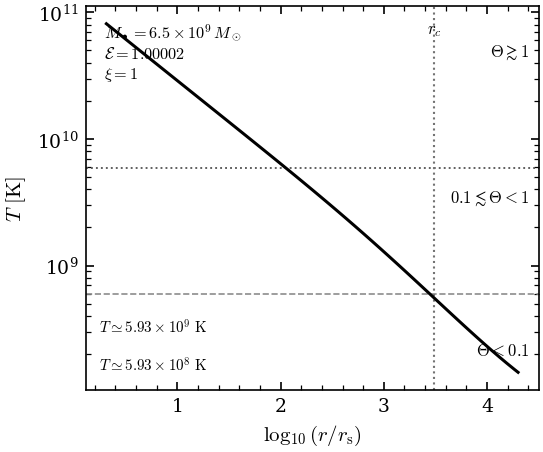

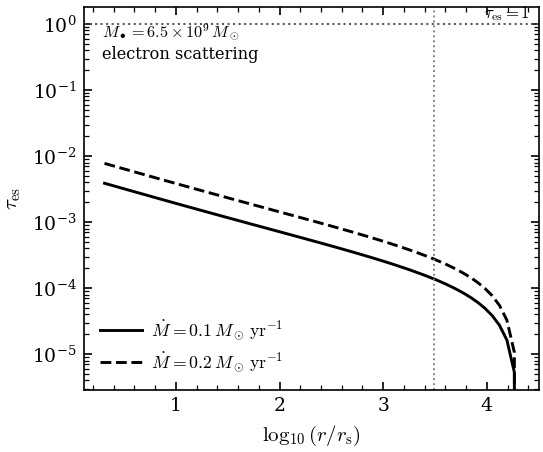

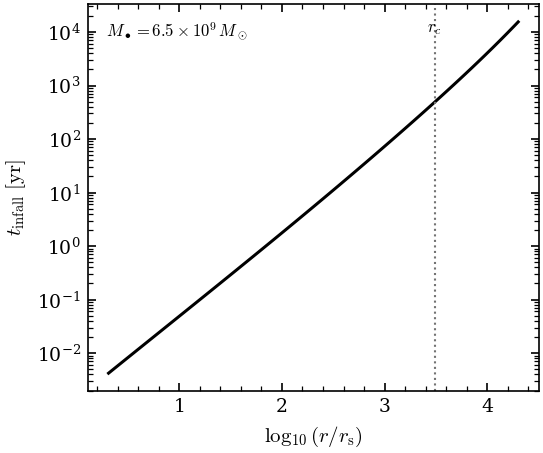

In [16]:
"""
====================================================================
M87 Accretion Flow: Temperature, Optical Depth and Infall Timescale
====================================================================

This script reads an already-generated accretion-flow .dat file.

Expected data columns:

    r    theta    u    c_s    M

where

    r       = dimensionless radius R/r_s
    theta   = dimensionless temperature Theta
    u       = dimensionless radial three-velocity
    c_s     = dimensionless sound speed
    M       = Mach number = u/c_s

The script produces:

    1. Physical temperature T(r)
    2. Electron-scattering optical depth tau_es(r)
    3. Infall timescale t_infall(r)

No hydrodynamical integration is performed.

--------------------------------------------------------------------
BLACK-HOLE PARAMETERS
--------------------------------------------------------------------

Black-hole mass:

    M_BH = 6.5 x 10^9 M_sun

This is the central value reported by:

    Event Horizon Telescope Collaboration,

    "First M87 Event Horizon Telescope Results. VI.
     The Shadow and Mass of the Central Black Hole",

    The Astrophysical Journal Letters,
    Volume 875, L6 (2019)

    DOI: 10.3847/2041-8213/ab1141

The EHT measurement is:

    M_BH = (6.5 +/- 0.7) x 10^9 M_sun

This script uses:

    M_BH = 6.5 x 10^9 M_sun

--------------------------------------------------------------------
ACCRETION RATES
--------------------------------------------------------------------

For optical depth:

    Mdot = 0.1 and 0.2 M_sun yr^-1

The temperature and infall timescale do not depend on Mdot for
the present dimensionless dynamical solution.

--------------------------------------------------------------------
THERMAL TEMPERATURE
--------------------------------------------------------------------

The dimensionless temperature is assumed to be

    Theta = k_B T / (m_e c^2)

therefore

    T = Theta m_e c^2 / k_B

       = 5.9309 x 10^9 Theta K.

--------------------------------------------------------------------
OPTICAL DEPTH
--------------------------------------------------------------------

Electron-scattering optical depth:

    tau_es(r) = integral_r^infinity kappa_es rho(R) dR

with

    rho(R) =
        Mdot / [4 pi R^2 u c]

and

    kappa_es = sigma_T / m_p.

The numerical integration is performed from the outermost
available radius inward.

--------------------------------------------------------------------
INFALL TIMESCALE
--------------------------------------------------------------------

Using u as the dimensionless radial three-velocity,

    u_phys = u c

and

    R = r r_s,

the local infall timescale is

    t_infall = R / u_phys

              = r r_s / (u c).

This is plotted in years.

====================================================================
"""

# ================================================================
# Imports
# ================================================================

import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# ================================================================
# Publication-quality Matplotlib settings
# ================================================================

plt.rcParams.update({

    "font.family": "serif",

    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    "axes.labelsize": 10,
    "axes.titlesize": 10,

    "axes.linewidth": 0.8,

    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    "lines.linewidth": 1.35,

    "legend.fontsize": 8.5,
    "legend.frameon": False,
    "legend.handlelength": 2.4,
    "legend.handletextpad": 0.5,
})


# ================================================================
# Physical constants -- CGS
# ================================================================

G = 6.67430e-8
# cm^3 g^-1 s^-2

c = 2.99792458e10
# cm s^-1

k_B = 1.380649e-16
# erg K^-1

m_e = 9.1093837139e-28
# g

m_p = 1.67262192369e-24
# g

sigma_T = 6.6524587321e-25
# cm^2

M_sun = 1.98847e33
# g

year = 365.25 * 24.0 * 3600.0
# s


# ================================================================
# Black-hole mass
# ================================================================

M_BH_solar = 6.5e9

M_BH = (
    M_BH_solar
    * M_sun
)


# ================================================================
# Schwarzschild radius
# ================================================================

r_s = (
    2.0
    * G
    * M_BH
    / c**2
)


# ================================================================
# Electron-scattering opacity
#
# For fully ionized hydrogen:
#
#     kappa_es = sigma_T / m_p
#
# approximately 0.398 cm^2 g^-1.
# ================================================================

kappa_es = (
    sigma_T
    / m_p
)


# ================================================================
# Input solution
#
# Change this filename if necessary.
# ================================================================

solution_file = Path(
    "solutions/accretion_E1.000020_xi1.000.dat"
)


# ================================================================
# Output directory
# ================================================================

figure_dir = Path(
    "figures"
)

figure_dir.mkdir(
    exist_ok=True
)


# ================================================================
# Accretion rates
#
# These are the values requested for the optical-depth calculation.
# ================================================================

Mdot_values = np.array([
    0.1,
    0.2
])


Mdot_cgs = (
    Mdot_values
    * M_sun
    / year
)


# ================================================================
# Read metadata from the .dat header
# ================================================================

def read_metadata(filename):

    metadata = {}

    with open(filename, "r") as file:

        for line in file:

            if not line.startswith("#"):
                continue

            line = line[1:].strip()

            # ------------------------------------------------
            # E
            # ------------------------------------------------

            match = re.match(
                r"^E\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["E"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # xi
            # ------------------------------------------------

            match = re.match(
                r"^xi\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["xi"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # theta_c
            # ------------------------------------------------

            match = re.match(
                r"^theta_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["theta_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # r_c
            # ------------------------------------------------

            match = re.match(
                r"^r_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["r_c"] = float(
                    match.group(1)
                )

            # ------------------------------------------------
            # u_c
            # ------------------------------------------------

            match = re.match(
                r"^u_c\s*=\s*([0-9.eE+-]+)",
                line
            )

            if match:

                metadata["u_c"] = float(
                    match.group(1)
                )

    return metadata


# ================================================================
# Check input file
# ================================================================

if not solution_file.exists():

    raise FileNotFoundError(
        "\nSolution file not found:\n"
        f"    {solution_file}\n\n"
        "Change 'solution_file' near the top of the script."
    )


# ================================================================
# Read metadata
# ================================================================

metadata = read_metadata(
    solution_file
)


E = metadata.get(
    "E",
    np.nan
)

xi = metadata.get(
    "xi",
    np.nan
)

r_c = metadata.get(
    "r_c",
    np.nan
)


# ================================================================
# Load numerical data
# ================================================================

data = np.loadtxt(
    solution_file,
    comments="#"
)


if data.ndim != 2:

    raise RuntimeError(
        "The .dat file does not contain a 2D data array."
    )


if data.shape[1] < 5:

    raise RuntimeError(
        "Expected at least five columns:\n"
        "r, theta, u, c_s, M"
    )


# ================================================================
# Extract columns
# ================================================================

r = data[:, 0]

theta = data[:, 1]

u = data[:, 2]

cs = data[:, 3]

Mach = data[:, 4]


# ================================================================
# Remove invalid points
# ================================================================

valid = (
    np.isfinite(r)
    &
    np.isfinite(theta)
    &
    np.isfinite(u)
    &
    np.isfinite(cs)
    &
    np.isfinite(Mach)
    &
    (r > 0)
    &
    (u > 0)
)


r = r[valid]

theta = theta[valid]

u = u[valid]

cs = cs[valid]

Mach = Mach[valid]


# ================================================================
# Sort by radius
#
# This is important for optical-depth integration.
# ================================================================

order = np.argsort(
    r
)


r = r[order]

theta = theta[order]

u = u[order]

cs = cs[order]

Mach = Mach[order]


# ================================================================
# Physical radius
# ================================================================

R = r * r_s


# ================================================================
# Physical temperature
#
# Theta = k_B T / (m_e c^2)
#
# T = Theta m_e c^2 / k_B
# ================================================================

T = (
    theta
    * m_e
    * c**2
    / k_B
)


# ================================================================
# Infall timescale
#
# t = R / (u c)
# ================================================================

t_infall = (
    R
    /
    (u * c)
)


t_infall_years = (
    t_infall
    / year
)


# ================================================================
# Density and optical depth
# ================================================================

# ------------------------------------------------
# Physical velocity
# ------------------------------------------------

u_phys = u * c


# ------------------------------------------------
# Optical depth arrays
#
# tau[i] = integral from R[i] to R_outer
#
# We calculate the integral using the trapezoidal
# rule, working from the outside inward.
# ------------------------------------------------

tau_all = []


for mdot in Mdot_cgs:

    # ------------------------------------------------------------
    # Density:
    #
    # Mdot = 4 pi R^2 rho u_phys
    #
    # rho = Mdot / (4 pi R^2 u_phys)
    # ------------------------------------------------------------

    rho = (
        mdot
        /
        (
            4.0
            * np.pi
            * R**2
            * u_phys
        )
    )


    # ------------------------------------------------------------
    # Optical-depth integrand
    # ------------------------------------------------------------

    integrand = (
        kappa_es
        * rho
    )


    # ------------------------------------------------------------
    # Integrate from outer radius inward.
    #
    # Reverse arrays, integrate cumulatively, then reverse back.
    # ------------------------------------------------------------

    R_reverse = R[::-1]

    integrand_reverse = integrand[::-1]


    dR = np.diff(
        R_reverse
    )


    trapezoids = (
        0.5
        *
        (
            integrand_reverse[:-1]
            +
            integrand_reverse[1:]
        )
        *
        dR
    )


    tau_reverse = np.zeros_like(
        R_reverse
    )


    tau_reverse[1:] = np.cumsum(
        trapezoids
    )


    tau = tau_reverse[::-1]


    # ------------------------------------------------------------
    # Since R_reverse decreases as we move through the reversed
    # array, the raw integral above is negative.
    #
    # Correct the sign.
    # ------------------------------------------------------------

    tau = -tau


    tau_all.append(
        tau
    )


tau_all = np.array(
    tau_all
)


# ################################################################
# ################################################################
#
# FIGURE 1
#
# PHYSICAL TEMPERATURE
#
# ################################################################
# ################################################################

fig, ax = plt.subplots(
    figsize=(3.7, 3.1)
)


# ================================================================
# Temperature curve
# ================================================================

ax.plot(
    np.log10(r),
    T,

    color="black",

    linewidth=1.45,

    label=r"$T(r)$",

    zorder=5
)


# ================================================================
# Thermal regimes
#
# Theta = 1 corresponds to:
#
#     T = m_e c^2 / k_B
#
#     approximately 5.93 x 10^9 K
#
# We use:
#
#     Theta < 0.1
#         non-relativistic thermal regime
#
#     0.1 <= Theta < 1
#         trans-relativistic regime
#
#     Theta >= 1
#         relativistically hot regime
#
# These boundaries are used as practical diagnostic markers,
# rather than as sharp physical phase transitions.
# ================================================================

T_theta_01 = (
    0.1
    * m_e
    * c**2
    / k_B
)


T_theta_1 = (
    m_e
    * c**2
    / k_B
)


# ================================================================
# Plot horizontal regime boundaries
# ================================================================

ax.axhline(
    T_theta_01,

    color="0.55",

    linestyle="--",

    linewidth=0.8
)


ax.axhline(
    T_theta_1,

    color="0.35",

    linestyle=":",

    linewidth=0.9
)


# ================================================================
# Locate critical radius
# ================================================================

if np.isfinite(r_c):

    x_c = np.log10(
        r_c
    )

    ax.axvline(
        x_c,

        color="0.45",

        linestyle=":",

        linewidth=1.0
    )

    ax.text(
        x_c,
        0.96,

        r"$r_c$",

        transform=ax.get_xaxis_transform(),

        fontsize=8,

        ha="center",
        va="top"
    )


# ================================================================
# Regime labels
# ================================================================

ax.text(
    0.98,
    0.08,

    r"$\Theta<0.1$",

    transform=ax.transAxes,

    fontsize=8,

    ha="right",
    va="bottom"
)


ax.text(
    0.98,
    0.50,

    r"$0.1\lesssim\Theta<1$",

    transform=ax.transAxes,

    fontsize=8,

    ha="right",
    va="center"
)


ax.text(
    0.98,
    0.88,

    r"$\Theta\gtrsim1$",

    transform=ax.transAxes,

    fontsize=8,

    ha="right",
    va="center"
)


# ================================================================
# Temperature labels
# ================================================================

ax.text(
    0.03,
    0.04,

    r"$T\simeq5.93\times10^8\ {\rm K}$",

    transform=ax.transAxes,

    fontsize=7.2,

    ha="left",
    va="bottom"
)


ax.text(
    0.03,
    0.14,

    r"$T\simeq5.93\times10^9\ {\rm K}$",

    transform=ax.transAxes,

    fontsize=7.2,

    ha="left",
    va="bottom"
)


# ================================================================
# Log temperature
# ================================================================

ax.set_yscale(
    "log"
)


# ================================================================
# Labels
# ================================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$"
)

ax.set_ylabel(
    r"$T\ [{\rm K}]$"
)


# ================================================================
# Parameter annotation
# ================================================================

parameter_text = (
    fr"$M_\bullet={M_BH_solar/1e9:.1f}"
    r"\times10^9\,M_\odot$"
)

if np.isfinite(E):

    parameter_text += (
        "\n"
        fr"$\mathcal{{E}}={E:.5f}$"
    )

if np.isfinite(xi):

    parameter_text += (
        "\n"
        fr"$\xi={xi:g}$"
    )


ax.text(
    0.04,
    0.96,

    parameter_text,

    transform=ax.transAxes,

    fontsize=7.8,

    ha="left",
    va="top"
)


# ================================================================
# Ticks
# ================================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True
)


ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)


ax.minorticks_on()


# ================================================================
# Spines
# ================================================================

for spine in ax.spines.values():

    spine.set_linewidth(0.8)


fig.tight_layout(
    pad=0.5
)


temperature_file = (
    figure_dir
    /
    "physical_temperature.pdf"
)


fig.savefig(
    temperature_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


fig.savefig(
    temperature_file.with_suffix(".png"),

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ################################################################
# ################################################################
#
# FIGURE 2
#
# ELECTRON-SCATTERING OPTICAL DEPTH
#
# ################################################################
# ################################################################

fig, ax = plt.subplots(
    figsize=(3.7, 3.1)
)


# ================================================================
# Plot optical depths
# ================================================================

line_styles = [
    "-",
    "--"
]


for mdot_value, tau, linestyle in zip(
    Mdot_values,
    tau_all,
    line_styles
):

    ax.plot(
        np.log10(r),
        tau,

        color="black",

        linestyle=linestyle,

        linewidth=1.4,

        label=(
            fr"$\dot M={mdot_value:g}\,"
            r"M_\odot\,{\rm yr}^{-1}$"
        )
    )


# ================================================================
# tau = 1
# ================================================================

ax.axhline(
    1.0,

    color="0.35",

    linestyle=":",

    linewidth=1.0
)


ax.text(
    0.98,
    1.03,

    r"$\tau_{\rm es}=1$",

    transform=ax.get_yaxis_transform(),

    fontsize=8,

    ha="right",
    va="bottom"
)


# ================================================================
# Critical radius
# ================================================================

if np.isfinite(r_c):

    ax.axvline(
        np.log10(r_c),

        color="0.5",

        linestyle=":",

        linewidth=0.9
    )


# ================================================================
# Log optical depth
# ================================================================

ax.set_yscale(
    "log"
)


# ================================================================
# Labels
# ================================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$"
)

ax.set_ylabel(
    r"$\tau_{\rm es}$"
)


# ================================================================
# Parameter information
# ================================================================

ax.text(
    0.04,
    0.96,

    (
        fr"$M_\bullet={M_BH_solar/1e9:.1f}"
        r"\times10^9\,M_\odot$"
        "\n"
        r"electron scattering"
    ),

    transform=ax.transAxes,

    fontsize=7.8,

    ha="left",
    va="top"
)


# ================================================================
# Ticks
# ================================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True
)


ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)


ax.minorticks_on()


# ================================================================
# Legend
# ================================================================

ax.legend(
    loc="best",

    frameon=False
)


# ================================================================
# Spines
# ================================================================

for spine in ax.spines.values():

    spine.set_linewidth(0.8)


fig.tight_layout(
    pad=0.5
)


optical_depth_file = (
    figure_dir
    /
    "electron_scattering_optical_depth.pdf"
)


fig.savefig(
    optical_depth_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


fig.savefig(
    optical_depth_file.with_suffix(".png"),

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ################################################################
# ################################################################
#
# FIGURE 3
#
# INFALL TIMESCALE
#
# ################################################################
# ################################################################

fig, ax = plt.subplots(
    figsize=(3.7, 3.1)
)


# ================================================================
# Infall time
# ================================================================

ax.plot(
    np.log10(r),
    t_infall_years,

    color="black",

    linewidth=1.45
)


# ================================================================
# Critical radius
# ================================================================

if np.isfinite(r_c):

    ax.axvline(
        np.log10(r_c),

        color="0.45",

        linestyle=":",

        linewidth=1.0
    )

    ax.text(
        np.log10(r_c),
        0.96,

        r"$r_c$",

        transform=ax.get_xaxis_transform(),

        fontsize=8,

        ha="center",
        va="top"
    )


# ================================================================
# Log timescale
# ================================================================

ax.set_yscale(
    "log"
)


# ================================================================
# Labels
# ================================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$"
)

ax.set_ylabel(
    r"$t_{\rm infall}\ [{\rm yr}]$"
)


# ================================================================
# Parameter information
# ================================================================

ax.text(
    0.04,
    0.96,

    (
        fr"$M_\bullet={M_BH_solar/1e9:.1f}"
        r"\times10^9\,M_\odot$"
    ),

    transform=ax.transAxes,

    fontsize=8,

    ha="left",
    va="top"
)


# ================================================================
# Ticks
# ================================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    length=4.0,
    width=0.8,

    top=True,
    right=True
)


ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=2.5,
    width=0.6,

    top=True,
    right=True
)


ax.minorticks_on()


# ================================================================
# Spines
# ================================================================

for spine in ax.spines.values():

    spine.set_linewidth(0.8)


fig.tight_layout(
    pad=0.5
)


infall_file = (
    figure_dir
    /
    "infall_timescale.pdf"
)


fig.savefig(
    infall_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


fig.savefig(
    infall_file.with_suffix(".png"),

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ################################################################
# ################################################################
#
# PRINT SUMMARY
#
# ################################################################
# ################################################################

print()
print("=" * 72)
print(
    "M87 ACCRETION-FLOW THERMODYNAMIC DIAGNOSTICS"
)
print("=" * 72)

print()

print(
    f"Solution file:"
    f"\n    {solution_file}"
)

print()

print(
    f"M_BH = {M_BH_solar:.3e} M_sun"
)

print(
    f"r_s  = {r_s:.6e} cm"
)

print(
    f"r_s  = {r_s / 1.495978707e13:.3f} AU"
)

print()

if np.isfinite(E):

    print(
        f"E  = {E:.8e}"
    )

if np.isfinite(xi):

    print(
        f"xi = {xi:.8e}"
    )

if np.isfinite(r_c):

    print(
        f"r_c = {r_c:.8e}"
    )

print()

print(
    f"kappa_es = {kappa_es:.6f} cm^2 g^-1"
)

print()

print(
    "Temperature conversion:"
)

print(
    "    T = Theta m_e c^2 / k_B"
)

print(
    f"    m_e c^2/k_B = "
    f"{m_e*c**2/k_B:.6e} K"
)

print()

print(
    "Accretion rates used for optical depth:"
)

for mdot, mdot_cgs_value in zip(
    Mdot_values,
    Mdot_cgs
):

    print(
        f"    {mdot:g} M_sun/yr"
        f" = {mdot_cgs_value:.6e} g/s"
    )

print()

print(
    "Optical depth at the inner boundary:"
)

for mdot, tau in zip(
    Mdot_values,
    tau_all
):

    print(
        f"    Mdot = {mdot:g}: "
        f"tau_es(r_min) = {tau[0]:.6e}"
    )

print()

print(
    "Infall timescale:"
)

print(
    f"    minimum = {t_infall_years.min():.6e} yr"
)

print(
    f"    maximum = {t_infall_years.max():.6e} yr"
)

print()

print(
    "Figures written to:"
)

print(
    f"    {temperature_file}"
)

print(
    f"    {optical_depth_file}"
)

print(
    f"    {infall_file}"
)

print()
print("=" * 72)


# ================================================================
# Show figures
# ================================================================

plt.show()


M87 ELECTRON-SCATTERING OPTICAL DEPTH

Input file:
    solutions/accretion_E1.000020_xi1.000.dat

M_BH = 6.500e+09 M_sun
r_s  = 1.919671e+15 cm
r_s  = 128.3221 AU

Numerical radial range:
    r_min = 2.050000e+00
    r_max = 2.000000e+04

Physical radial range:
    R_min = 3.935325e+15 cm
    R_max = 3.839341e+19 cm

Electron-scattering opacity:
    kappa_es = 0.397726 cm^2 g^-1

Mdot = 0.100 M_sun yr^-1
    Mdot = 6.301081e+24 g s^-1
    rho(r_min) = 1.094764e-18 g cm^-3
    rho(r_max) = 4.314142e-24 g cm^-3
    tau(r_min) = 3.876837e-03
    tau(r_max) = 0.000000e+00

Mdot = 0.200 M_sun yr^-1
    Mdot = 1.260216e+25 g s^-1
    rho(r_min) = 2.189528e-18 g cm^-3
    rho(r_max) = 8.628283e-24 g cm^-3
    tau(r_min) = 7.753675e-03
    tau(r_max) = 0.000000e+00

OPTICAL DEPTH SUMMARY

Mdot = 0.1 M_sun yr^-1
    tau_es(r_min) = 3.876837e-03
    tau_es(r_max) = 0.000000e+00
    No tau_es = 1 crossing within the numerical domain.

Mdot = 0.2 M_sun yr^-1
    tau_es(r_min) = 7.753675e-03
    t

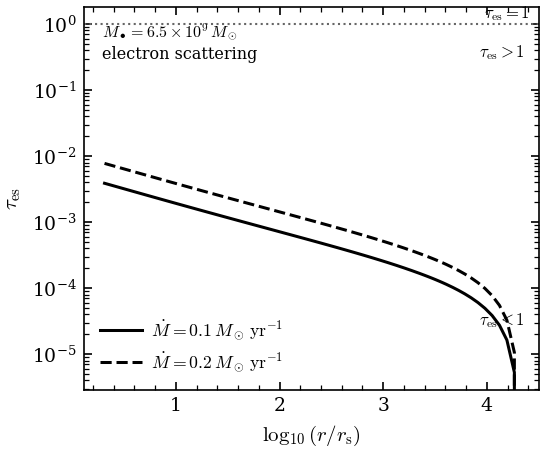

In [18]:
"""
====================================================================
Electron-Scattering Optical Depth of the M87 Accretion Flow
====================================================================

Standalone post-processing script.

The script reads a previously generated accretion-flow .dat file
with columns:

    r       theta       u       c_s       M

where:

    r       = R / r_s
    theta   = dimensionless temperature
    u       = dimensionless radial three-velocity
    c_s     = dimensionless sound speed
    M       = Mach number = u/c_s

No hydrodynamic integration is performed.

--------------------------------------------------------------------
PHYSICAL MODEL
--------------------------------------------------------------------

The physical radius is

    R = r r_s

where

    r_s = 2 G M_BH / c^2.

The physical radial velocity is

    v = u c.

For a steady spherical flow,

    Mdot = 4 pi R^2 rho v,

therefore

    rho(R) = Mdot / [4 pi R^2 u c].

The electron-scattering opacity is

    kappa_es = sigma_T / m_p

for fully ionized hydrogen.

The electron-scattering optical depth measured from radius R
to the outer edge of the numerical solution is

    tau_es(R)
        = integral_R^Rout kappa_es rho(R') dR'.

Thus:

    tau_es << 1     optically thin
    tau_es ~ 1      transition / photospheric condition
    tau_es >> 1     optically thick

--------------------------------------------------------------------
BLACK-HOLE MASS
--------------------------------------------------------------------

M_BH = 6.5 x 10^9 M_sun

Reference:

Event Horizon Telescope Collaboration,

"First M87 Event Horizon Telescope Results. VI.
 The Shadow and Mass of the Central Black Hole"

The Astrophysical Journal Letters,
Volume 875, L6 (2019)

DOI:
10.3847/2041-8213/ab1141

BibTeX:

@article{EHT_M87_Mass_2019,
   title={First M87 Event Horizon Telescope Results. VI.
          The Shadow and Mass of the Central Black Hole},
   volume={875},
   ISSN={2041-8213},
   DOI={10.3847/2041-8213/ab1141},
   number={1},
   journal={The Astrophysical Journal Letters},
   publisher={The American Astronomical Society},
   author={The Event Horizon Telescope Collaboration},
   year={2019},
   month={Apr},
   pages={L6}
}

--------------------------------------------------------------------
ACCRETION RATES
--------------------------------------------------------------------

The following accretion rates are used:

    Mdot = 0.1 M_sun yr^-1
    Mdot = 0.2 M_sun yr^-1

--------------------------------------------------------------------
IMPORTANT NUMERICAL POINT
--------------------------------------------------------------------

The optical depth is integrated only up to the largest radius
contained in the saved .dat file:

    tau(r) = integral_r^r_out ...

This means r_out is the outer boundary of the saved solution.

For your current calculation this should correspond approximately
to r_max = 20000.

--------------------------------------------------------------------
"""

# ================================================================
# Imports
# ================================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid


# ================================================================
# Publication-quality Matplotlib settings
# ================================================================

plt.rcParams.update({

    "font.family": "serif",

    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    "axes.labelsize": 10,

    "axes.linewidth": 0.8,

    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "xtick.minor.size": 2.5,
    "ytick.minor.size": 2.5,

    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    "lines.linewidth": 1.4,

    "legend.fontsize": 8.5,

    "legend.frameon": False,
})


# ================================================================
# CGS physical constants
# ================================================================

G = 6.67430e-8
# gravitational constant [cm^3 g^-1 s^-2]

c = 2.99792458e10
# speed of light [cm s^-1]

m_p = 1.67262192369e-24
# proton mass [g]

sigma_T = 6.6524587321e-25
# Thomson cross section [cm^2]

M_sun = 1.98847e33
# solar mass [g]

year = 365.25 * 24.0 * 3600.0
# one year [s]


# ================================================================
# Black-hole mass
# ================================================================

M_BH_solar = 6.5e9

M_BH = (
    M_BH_solar
    * M_sun
)


# ================================================================
# Schwarzschild radius
# ================================================================

r_s = (
    2.0
    * G
    * M_BH
    / c**2
)


# ================================================================
# Electron-scattering opacity
#
# Fully ionized hydrogen:
#
#     kappa_es = sigma_T / m_p
# ================================================================

kappa_es = (
    sigma_T
    / m_p
)


# ================================================================
# INPUT FILE
#
# Change this to the location of your saved accretion solution.
# ================================================================

solution_file = Path(
    "solutions/accretion_E1.000020_xi1.000.dat"
)


# ================================================================
# ACCRETION RATES
#
# Units: solar masses per year
# ================================================================

Mdot_values = np.array([
    0.1,
    0.2
])


# Convert to g/s

Mdot_cgs = (
    Mdot_values
    * M_sun
    / year
)


# ================================================================
# OUTPUT FIGURE
# ================================================================

output_file = Path(
    "electron_scattering_optical_depth.pdf"
)


# ================================================================
# Check input file
# ================================================================

if not solution_file.exists():

    raise FileNotFoundError(
        "\nCould not find the input file:\n"
        f"    {solution_file}\n\n"
        "Please change 'solution_file' in the script."
    )


# ================================================================
# Load data
#
# Columns:
#
#     0 = r
#     1 = theta
#     2 = u
#     3 = c_s
#     4 = Mach number
# ================================================================

data = np.loadtxt(
    solution_file,
    comments="#"
)


if data.ndim != 2:

    raise RuntimeError(
        "The input file does not contain a valid 2D data array."
    )


if data.shape[1] < 5:

    raise RuntimeError(
        "The input file must contain at least five columns:\n"
        "r, theta, u, c_s, M"
    )


# ================================================================
# Extract columns
# ================================================================

r = data[:, 0]

theta = data[:, 1]

u = data[:, 2]

cs = data[:, 3]

Mach = data[:, 4]


# ================================================================
# Remove invalid values
# ================================================================

valid = (
    np.isfinite(r)
    &
    np.isfinite(theta)
    &
    np.isfinite(u)
    &
    np.isfinite(cs)
    &
    np.isfinite(Mach)
    &
    (r > 0.0)
    &
    (u > 0.0)
)


r = r[valid]

theta = theta[valid]

u = u[valid]

cs = cs[valid]

Mach = Mach[valid]


# ================================================================
# Sort according to radius
# ================================================================

order = np.argsort(r)

r = r[order]

theta = theta[order]

u = u[order]

cs = cs[order]

Mach = Mach[order]


# ================================================================
# Physical radius
#
# R = r r_s
# ================================================================

R = (
    r
    * r_s
)


# ================================================================
# Physical velocity
#
# u is dimensionless.
#
# v_phys = u c
# ================================================================

v_phys = (
    u
    * c
)


# ================================================================
# Print basic information
# ================================================================

print()
print("=" * 72)
print("M87 ELECTRON-SCATTERING OPTICAL DEPTH")
print("=" * 72)

print()

print(
    f"Input file:"
    f"\n    {solution_file}"
)

print()

print(
    f"M_BH = {M_BH_solar:.3e} M_sun"
)

print(
    f"r_s  = {r_s:.6e} cm"
)

print(
    f"r_s  = {r_s / 1.495978707e13:.4f} AU"
)

print()

print(
    f"Numerical radial range:"
)

print(
    f"    r_min = {r.min():.6e}"
)

print(
    f"    r_max = {r.max():.6e}"
)

print()

print(
    f"Physical radial range:"
)

print(
    f"    R_min = {R.min():.6e} cm"
)

print(
    f"    R_max = {R.max():.6e} cm"
)

print()

print(
    f"Electron-scattering opacity:"
)

print(
    f"    kappa_es = {kappa_es:.6f} cm^2 g^-1"
)

print()


# ================================================================
# Calculate optical depth
# ================================================================

tau_all = []


for mdot in Mdot_cgs:

    # ------------------------------------------------------------
    # Density
    #
    # Mdot = 4 pi R^2 rho v
    #
    # rho = Mdot / (4 pi R^2 v)
    # ------------------------------------------------------------

    rho = (
        mdot
        /
        (
            4.0
            * np.pi
            * R**2
            * v_phys
        )
    )


    # ------------------------------------------------------------
    # Absorption/scattering coefficient
    #
    # alpha_es = kappa_es rho
    #
    # units: cm^-1
    # ------------------------------------------------------------

    alpha_es = (
        kappa_es
        * rho
    )


    # ------------------------------------------------------------
    # Calculate:
    #
    # I(R) = integral_Rmin^R alpha(R') dR'
    #
    # using the cumulative trapezoidal rule.
    # ------------------------------------------------------------

    cumulative_integral = cumulative_trapezoid(
        alpha_es,
        R,
        initial=0.0
    )


    # ------------------------------------------------------------
    # Total optical depth from R_min to R_out
    # ------------------------------------------------------------

    total_integral = (
        cumulative_integral[-1]
    )


    # ------------------------------------------------------------
    # Desired quantity:
    #
    # tau(R)
    #
    # = integral_R^Rout alpha(R') dR'
    #
    # = total_integral
    #   - integral_Rmin^R alpha(R') dR'
    # ------------------------------------------------------------

    tau = (
        total_integral
        - cumulative_integral
    )


    tau_all.append(
        tau
    )


    # ------------------------------------------------------------
    # Print density information
    # ------------------------------------------------------------

    print(
        f"Mdot = "
        f"{mdot / M_sun * year:.3f} M_sun yr^-1"
    )

    print(
        f"    Mdot = {mdot:.6e} g s^-1"
    )

    print(
        f"    rho(r_min) = {rho[0]:.6e} g cm^-3"
    )

    print(
        f"    rho(r_max) = {rho[-1]:.6e} g cm^-3"
    )

    print(
        f"    tau(r_min) = {tau[0]:.6e}"
    )

    print(
        f"    tau(r_max) = {tau[-1]:.6e}"
    )

    print()


# Convert to NumPy array

tau_all = np.asarray(
    tau_all
)


# ================================================================
# Locate tau = 1 radius
# ================================================================

tau_one_radii = []


for tau in tau_all:

    # ------------------------------------------------------------
    # We search for a crossing of tau = 1.
    # ------------------------------------------------------------

    crossing = np.where(
        np.diff(
            np.sign(
                tau - 1.0
            )
        )
        != 0
    )[0]


    if len(crossing) == 0:

        tau_one_radii.append(
            np.nan
        )

        continue


    i = crossing[0]


    # ------------------------------------------------------------
    # Interpolate in log radius versus log optical depth.
    #
    # This is more appropriate because both quantities can span
    # several orders of magnitude.
    # ------------------------------------------------------------

    x1 = np.log10(
        r[i]
    )

    x2 = np.log10(
        r[i + 1]
    )

    y1 = np.log10(
        tau[i]
    )

    y2 = np.log10(
        tau[i + 1]
    )


    # Solve for log10(r) at tau = 1,
    # i.e. log10(tau) = 0.

    if y2 != y1:

        x_tau1 = (
            x1
            +
            (0.0 - y1)
            * (x2 - x1)
            / (y2 - y1)
        )

        r_tau1 = (
            10.0**x_tau1
        )

    else:

        r_tau1 = (
            0.5
            * (
                r[i]
                +
                r[i + 1]
            )
        )


    tau_one_radii.append(
        r_tau1
    )


# ================================================================
# Create figure
# ================================================================

fig, ax = plt.subplots(
    figsize=(3.7, 3.1)
)


# ================================================================
# Plot optical depth
# ================================================================

line_styles = [
    "-",
    "--"
]


for mdot_value, tau, linestyle, r_tau1 in zip(
    Mdot_values,
    tau_all,
    line_styles,
    tau_one_radii
):

    ax.plot(
        np.log10(r),
        tau,

        color="black",

        linestyle=linestyle,

        linewidth=1.45,

        label=(
            fr"$\dot M={mdot_value:g}\,"
            r"M_\odot\,{\rm yr}^{-1}$"
        )
    )


    # ------------------------------------------------------------
    # Mark tau = 1 radius if it exists
    # ------------------------------------------------------------

    if np.isfinite(r_tau1):

        ax.plot(
            np.log10(r_tau1),
            1.0,

            marker="o",

            markersize=4.0,

            markerfacecolor="white",

            markeredgecolor="black",

            markeredgewidth=0.9
        )


# ================================================================
# tau = 1 line
# ================================================================

ax.axhline(
    1.0,

    color="0.4",

    linestyle=":",

    linewidth=1.0
)


ax.text(
    0.98,
    1.03,

    r"$\tau_{\rm es}=1$",

    transform=ax.get_yaxis_transform(),

    fontsize=8,

    ha="right",

    va="bottom"
)


# ================================================================
# Optically thick / thin labels
# ================================================================

ax.text(
    0.97,
    0.88,

    r"$\tau_{\rm es}>1$",

    transform=ax.transAxes,

    fontsize=8,

    ha="right",

    va="center"
)


ax.text(
    0.97,
    0.18,

    r"$\tau_{\rm es}<1$",

    transform=ax.transAxes,

    fontsize=8,

    ha="right",

    va="center"
)


# ================================================================
# Axis labels
# ================================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$"
)

ax.set_ylabel(
    r"$\tau_{\rm es}$"
)


# ================================================================
# Logarithmic optical-depth axis
# ================================================================

ax.set_yscale(
    "log"
)


# ================================================================
# Legend
# ================================================================

ax.legend(
    loc="best",

    frameon=False
)


# ================================================================
# Parameter annotation
# ================================================================

ax.text(
    0.04,
    0.96,

    (
        r"$M_\bullet=6.5\times10^9\,M_\odot$"
        "\n"
        r"electron scattering"
    ),

    transform=ax.transAxes,

    fontsize=7.7,

    ha="left",

    va="top"
)


# ================================================================
# Tick configuration
# ================================================================

ax.tick_params(
    axis="both",

    which="major",

    direction="in",

    length=4.0,

    width=0.8,

    top=True,

    right=True
)


ax.tick_params(
    axis="both",

    which="minor",

    direction="in",

    length=2.5,

    width=0.6,

    top=True,

    right=True
)


ax.minorticks_on()


# ================================================================
# Spines
# ================================================================

for spine in ax.spines.values():

    spine.set_linewidth(
        0.8
    )


# ================================================================
# Layout
# ================================================================

fig.tight_layout(
    pad=0.5
)


# ================================================================
# Save PDF
# ================================================================

fig.savefig(
    output_file,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ================================================================
# Also save PNG
# ================================================================

png_file = output_file.with_suffix(
    ".png"
)


fig.savefig(
    png_file,

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03
)


# ================================================================
# Final numerical summary
# ================================================================

print("=" * 72)
print("OPTICAL DEPTH SUMMARY")
print("=" * 72)

print()

for mdot_value, tau, r_tau1 in zip(
    Mdot_values,
    tau_all,
    tau_one_radii
):

    print(
        f"Mdot = {mdot_value:g} M_sun yr^-1"
    )

    print(
        f"    tau_es(r_min) = "
        f"{tau[0]:.6e}"
    )

    print(
        f"    tau_es(r_max) = "
        f"{tau[-1]:.6e}"
    )


    if np.isfinite(r_tau1):

        print(
            f"    tau_es = 1 at "
            f"r = {r_tau1:.6e} r_s"
        )

    else:

        print(
            "    No tau_es = 1 crossing "
            "within the numerical domain."
        )

    print()


print(
    f"Figure saved as:\n"
    f"    {output_file}\n"
    f"    {png_file}"
)

print()

print("=" * 72)


# ================================================================
# Display
# ================================================================

plt.show()

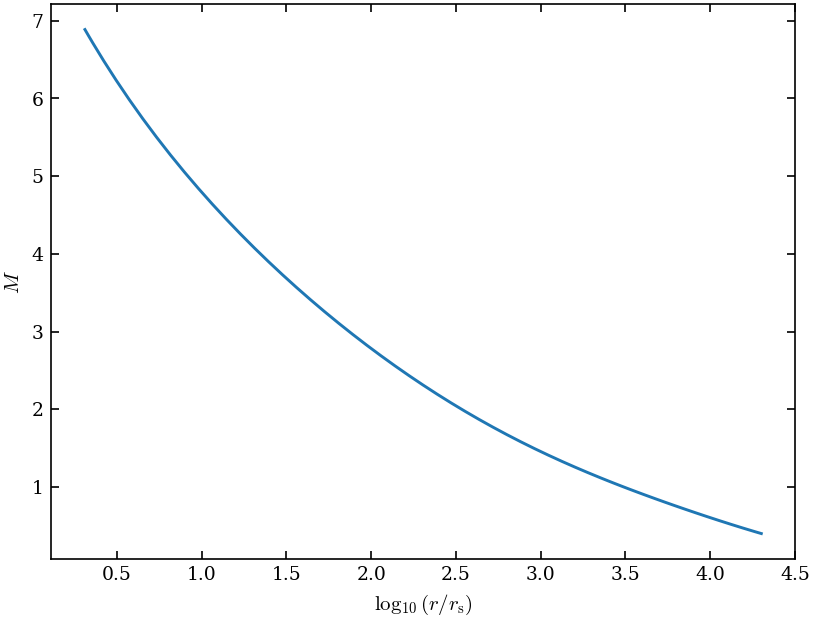

In [21]:
import numpy as np
import matplotlib.pyplot as plt

filename = "solutions/accretion_E1.000020_xi1.000.dat"

data = np.loadtxt(filename, comments="#")

r_acc     = data[:, 0]
theta_acc = data[:, 1]
v_acc     = data[:, 2]
a_acc     = data[:, 3]
M_acc     = data[:, 4]

plt.plot(
    np.log10(r_acc),
    M_acc
)

plt.xlabel(r"$\log_{10}(r/r_{\rm s})$")
plt.ylabel(r"$M$")

plt.show()

Maximum relative difference between saved M and u/c_s = 1.035e-12
Critical radius from M = 1: r_c = 3078.918856


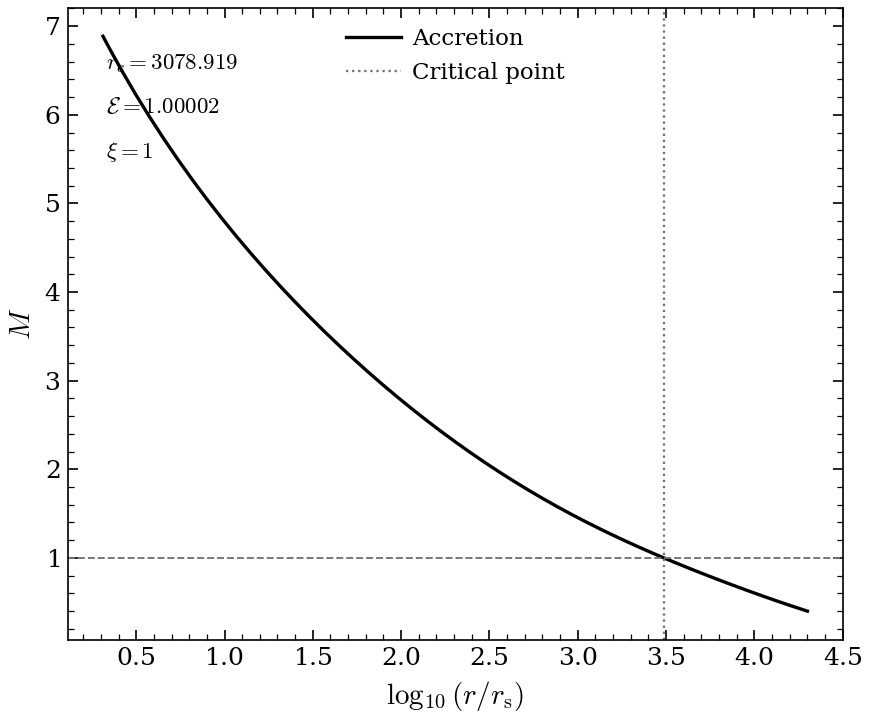

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl


# ================================================================
# INPUT PARAMETERS
# ================================================================

E = 1.00002
xi = 1.0

# Critical radius obtained from the original accretion calculation.
# This is used only for marking the critical point on the plot.
#
# If you want to obtain rc automatically from the .dat file,
# see the alternative method further below.
rc = 3.0


# ================================================================
# SAVED ACCRETION-BRANCH DATA
# ================================================================
#
# Columns in the file:
#
#     column 0 : r
#     column 1 : theta
#     column 2 : u
#     column 3 : c_s
#     column 4 : Mach number
#
# The file contains the ACCRETION BRANCH ONLY.
# ================================================================

filename = "solutions/accretion_E1.000020_xi1.000.dat"

data = np.loadtxt(
    filename,
    comments="#"
)


# ================================================================
# Extract accretion-branch quantities
# ================================================================

r_acc = data[:, 0]

theta_acc = data[:, 1]

u_acc = data[:, 2]

cs_acc = data[:, 3]

M_acc = data[:, 4]


# ================================================================
# Basic sanity checks
# ================================================================

if data.shape[1] < 5:

    raise ValueError(
        "The .dat file must contain at least 5 columns:\n"
        "r, theta, u, c_s, M"
    )


if np.any(r_acc <= 0):

    raise ValueError(
        "The radial coordinate contains non-positive values."
    )


# ================================================================
# Sort by radius
# ================================================================
#
# This is useful if the .dat file was generated from concatenated
# inward + outward integrations.
# ================================================================

order = np.argsort(r_acc)

r_acc = r_acc[order]

theta_acc = theta_acc[order]

u_acc = u_acc[order]

cs_acc = cs_acc[order]

M_acc = M_acc[order]


# ================================================================
# Verify Mach number
# ================================================================
#
# Since M = u/c_s, this gives us a useful consistency check.
# ================================================================

M_check = u_acc / cs_acc

relative_error = np.max(
    np.abs(
        M_acc - M_check
    )
    /
    np.maximum(
        np.abs(M_acc),
        1e-30
    )
)

print(
    f"Maximum relative difference between saved M "
    f"and u/c_s = {relative_error:.3e}"
)


# ================================================================
# Locate the critical point from M = 1
# ================================================================
#
# In the transonic accretion solution the sonic/critical point
# satisfies approximately
#
#                 M = 1.
#
# Rather than hard-coding rc, we can estimate its location from
# the saved data.
# ================================================================

crossing = np.where(
    np.diff(
        np.sign(M_acc - 1.0)
    ) != 0
)[0]


if len(crossing) > 0:

    i = crossing[0]

    # Linear interpolation in M(r)
    rc_from_data = (
        r_acc[i]
        +
        (1.0 - M_acc[i])
        *
        (
            r_acc[i + 1]
            -
            r_acc[i]
        )
        /
        (
            M_acc[i + 1]
            -
            M_acc[i]
        )
    )

    print(
        f"Critical radius from M = 1: "
        f"r_c = {rc_from_data:.6f}"
    )

    rc = rc_from_data

else:

    print(
        "Warning: no M = 1 crossing found in the saved data."
    )

    rc = None


# ================================================================
# Journal-style Matplotlib configuration
# ================================================================

mpl.rcParams.update({

    "font.family": "serif",

    "font.serif": [
        "Computer Modern Roman",
        "DejaVu Serif"
    ],

    "mathtext.fontset": "cm",

    "axes.labelsize": 14,

    "axes.linewidth": 0.8,

    "xtick.labelsize": 12,

    "ytick.labelsize": 12,

    "xtick.direction": "in",

    "ytick.direction": "in",

    "xtick.top": True,

    "ytick.right": True,

    "xtick.major.size": 5,

    "ytick.major.size": 5,

    "xtick.minor.size": 3,

    "ytick.minor.size": 3,

    "xtick.major.width": 0.8,

    "ytick.major.width": 0.8,

    "xtick.minor.width": 0.6,

    "ytick.minor.width": 0.6,

    "legend.fontsize": 11,

    "legend.frameon": False,

    "lines.linewidth": 1.6,
})


# ================================================================
# FIGURE
# ================================================================

fig, ax = plt.subplots(
    figsize=(6.0, 5.0)
)


# ================================================================
# Mach-number accretion curve
# ================================================================

ax.plot(
    np.log10(r_acc),
    M_acc,

    color="black",

    linestyle="-",

    linewidth=1.6,

    label="Accretion"
)


# ================================================================
# Critical point
# ================================================================

if rc is not None:

    ax.axvline(
        np.log10(rc),

        color="0.45",

        linestyle=":",

        linewidth=1.1,

        label="Critical point"
    )


# ================================================================
# Sonic condition
# ================================================================

ax.axhline(
    1.0,

    color="0.45",

    linestyle="--",

    linewidth=0.9
)


# ================================================================
# Labels
# ================================================================

ax.set_xlabel(
    r"$\log_{10}(r/r_{\rm s})$"
)

ax.set_ylabel(
    r"$M$"
)


# ================================================================
# Parameter information
# ================================================================

if rc is not None:

    ax.text(
        0.05,
        0.93,

        fr"$r_c={rc:.3f}$",

        transform=ax.transAxes,

        fontsize=11,

        ha="left",

        va="top"
    )

ax.text(
    0.05,
    0.86,

    fr"$\mathcal{{E}}={E:.5f}$",

    transform=ax.transAxes,

    fontsize=11,

    ha="left",

    va="top"
)

ax.text(
    0.05,
    0.79,

    fr"$\xi={xi:g}$",

    transform=ax.transAxes,

    fontsize=11,

    ha="left",

    va="top"
)


# ================================================================
# Legend
# ================================================================

ax.legend(
    loc="best",
    frameon=False
)


# ================================================================
# Minor ticks
# ================================================================

ax.minorticks_on()


# ================================================================
# Tick appearance
# ================================================================

ax.tick_params(
    axis="both",
    which="major",

    direction="in",

    top=True,
    right=True,

    length=5,
    width=0.8
)

ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    top=True,
    right=True,

    length=3,
    width=0.6
)


# ================================================================
# Layout
# ================================================================

fig.tight_layout()


# ================================================================
# Save figure
# ================================================================

fig.savefig(
    "mach_accretion.pdf",

    dpi=600,

    bbox_inches="tight"
)

fig.savefig(
    "mach_accretion.png",

    dpi=600,

    bbox_inches="tight"
)


# ================================================================
# Display
# ================================================================

plt.show()

### Carter-Penrose Diagram

Maximum relative error in M = u/c_s: 1.035e-12

 Critical point
r_c     = 3078.91885627
theta_c = 9.34307304e-02
u_c     = 1.27465219e-02
c_s,c   = 1.27465219e-02

N_c       = 1.67316173e+00
du/dr|_c  = -3.02752055e-06
dtheta/dr|_c = -2.30135826e-05

kappa_c   = 2.28897786e-04



/var/folders/gz/p0q5xkm90tb3knq8jxhq797m0000gn/T/ipykernel_86883/1650861091.py:510: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  return quad(
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


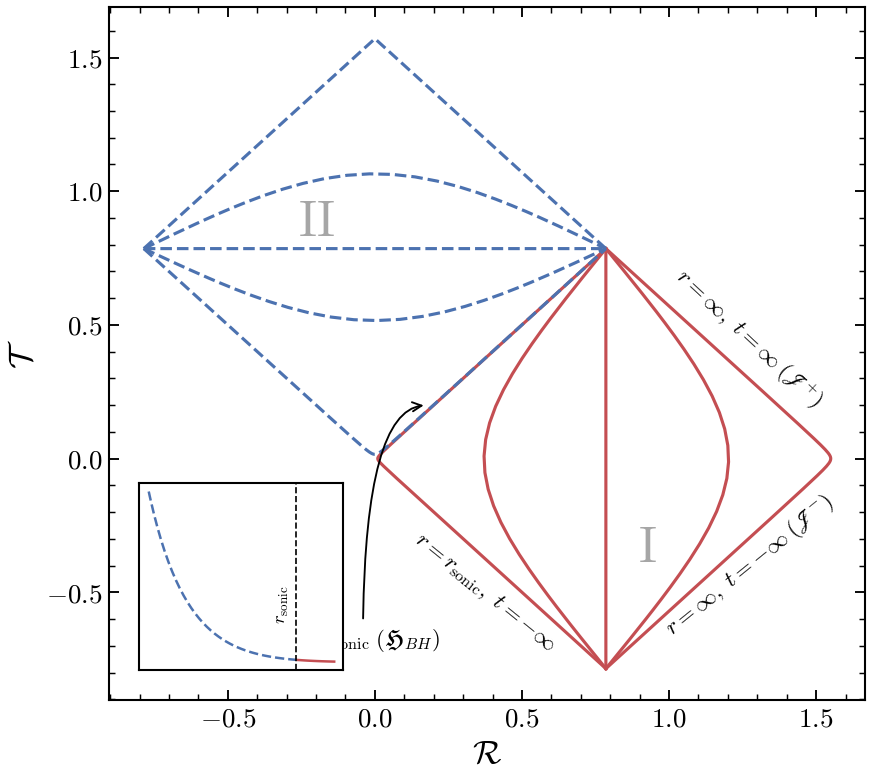


PCD calculation complete
Input file : solutions/accretion_E1.000020_xi1.000.dat
Output     : ap_pcd.pdf
E          : 1.00002000
xi         : 1.000
r_sonic    : 3078.91885627
theta_c    : 9.34307304e-02
c_s,c      : 1.27465219e-02
kappa_c    : 2.28897786e-04


In [41]:
# ================================================================
# Penrose-Carter Diagram for the Accretion Flow
#
# Streamlined PRD-style version
#
# Input:
#   Saved accretion solution:
#       r, theta, u, c_s, M
#
# Output:
#   ap_pcd.pdf
#
# The hydrodynamic solution is NOT recomputed here.
# ================================================================


import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.integrate import quad
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ================================================================
# 1. USER INPUT
# ================================================================

DATA_FILE = "solutions/accretion_E1.000020_xi1.000.dat"
OUTPUT_FILE = "ap_pcd.pdf"

E = 1.00002
xi = 1.0
eta = 1.0 / 1836.0


# ================================================================
# 2. PRD-STYLE PLOT SETTINGS
# ================================================================

plt.rcParams.update({

    # Font
    "font.family": "serif",
    "mathtext.fontset": "cm",

    # Figure
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Axes
    "axes.linewidth": 1.0,
    "axes.labelsize": 16,
    "axes.titlesize": 16,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.minor.size": 3,
    "ytick.minor.size": 3,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,

    # Legend
    "legend.fontsize": 12,

    # Lines
    "lines.linewidth": 1.5,

    # PDF
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ================================================================
# 3. COLOURS
# ================================================================

COLOR_OUT = "#C44E52"
COLOR_IN = "#4C72B0"


# ================================================================
# 4. LOAD ACCRETION SOLUTION
# ================================================================

data = np.loadtxt(
    DATA_FILE,
    comments="#"
)


r = data[:, 0]
theta = data[:, 1]
u = data[:, 2]
c_s = data[:, 3]
M = data[:, 4]


# Ensure increasing radius
order = np.argsort(r)

r = r[order]
theta = theta[order]
u = u[order]
c_s = c_s[order]
M = M[order]


# ================================================================
# 5. BASIC CONSISTENCY CHECK
# ================================================================

M_check = u / c_s

relative_error = np.max(
    np.abs(M - M_check)
    /
    np.maximum(np.abs(M), 1.0e-30)
)

print(
    f"Maximum relative error in M = u/c_s: "
    f"{relative_error:.3e}"
)


# ================================================================
# 6. FIND SONIC POINT
# ================================================================

crossings = np.where(
    np.diff(np.sign(M - 1.0)) != 0
)[0]


if len(crossings) == 0:
    raise RuntimeError(
        "No M = 1 crossing found in the saved accretion solution."
    )


i_c = crossings[0]


# Linear interpolation to M = 1
r_c = (
    r[i_c]
    +
    (1.0 - M[i_c])
    *
    (r[i_c + 1] - r[i_c])
    /
    (M[i_c + 1] - M[i_c])
)


# Critical-point quantities
theta_c = np.interp(r_c, r, theta)
u_c = np.interp(r_c, r, u)
a_c = np.interp(r_c, r, c_s)


print()
print("==========================================")
print(" Critical point")
print("==========================================")
print(f"r_c     = {r_c:.8f}")
print(f"theta_c = {theta_c:.8e}")
print(f"u_c     = {u_c:.8e}")
print(f"c_s,c   = {a_c:.8e}")
print("==========================================")
print()


# ================================================================
# 7. EQUATION OF STATE
# ================================================================

def f_func(theta):

    return (
        (2.0 - xi)
        * (
            1.0
            + theta * (9.0 * theta + 3.0)
            / (3.0 * theta + 2.0)
        )
        +
        xi
        * (
            1.0 / eta
            +
            theta * (9.0 * theta + 3.0 / eta)
            / (3.0 * theta + 2.0 / eta)
        )
    )


def df_dtheta(theta):

    term1 = (
        9.0 * theta + 3.0
    ) / (
        3.0 * theta + 2.0
    )

    term2 = (
        9.0 * theta
    ) / (
        3.0 * theta + 2.0
    )**2


    term3 = (
        9.0 * theta + 3.0 / eta
    ) / (
        3.0 * theta + 2.0 / eta
    )

    term4 = (
        9.0 * theta
    ) / (
        eta * (3.0 * theta + 2.0 / eta)**2
    )


    return (
        (2.0 - xi) * (term1 + term2)
        +
        xi * (term3 + term4)
    )


def N_func(theta):

    return 0.5 * df_dtheta(theta)


N_c = N_func(theta_c)


# ================================================================
# 8. DERIVATIVES FROM THE SAVED SOLUTION
# ================================================================

du_dr = np.gradient(
    u,
    r,
    edge_order=2
)


dtheta_dr = np.gradient(
    theta,
    r,
    edge_order=2
)


du_dr_c = np.interp(
    r_c,
    r,
    du_dr
)


dtheta_dr_c = np.interp(
    r_c,
    r,
    dtheta_dr
)


print(f"N_c       = {N_c:.8e}")
print(f"du/dr|_c  = {du_dr_c:.8e}")
print(f"dtheta/dr|_c = {dtheta_dr_c:.8e}")
print()


# ================================================================
# 9. METRIC COMPONENTS
#
# Keep these exactly as in your working PCD code.
# ================================================================

def G_tt(r, u, a):

    beta = 1.0 - 1.0 / a**2

    return (
        -(1.0 - 2.0 / r)
        +
        beta * u**2
    )


def G_rr(r, u, a):

    beta = 1.0 - 1.0 / a**2

    return (
        1.0 / (1.0 - 2.0 / r)
        +
        beta * u**2
        /
        (1.0 - 2.0 / r)**2
    )


def G_tr(r, u, a):

    beta = 1.0 - 1.0 / a**2

    return (
        beta * u
        /
        (1.0 - 2.0 / r)
    )


# ================================================================
# 10. INTERPOLATION OF FLOW VARIABLES
# ================================================================

u_interp = interp1d(
    r,
    u,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)


cs_interp = interp1d(
    r,
    c_s,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)


def u_0(radius):

    return -u_interp(radius)


def c_0(radius):

    return cs_interp(radius)


# ================================================================
# 11. NULL CHARACTERISTICS
# ================================================================

def A_plus(radius):

    velocity = u_0(radius)
    sound_speed = c_0(radius)

    gtt = G_tt(
        radius,
        velocity,
        sound_speed
    )

    grr = G_rr(
        radius,
        velocity,
        sound_speed
    )

    gtr = G_tr(
        radius,
        velocity,
        sound_speed
    )

    discriminant = (
        gtr**2
        -
        grr * gtt
    )

    discriminant = np.maximum(
        discriminant,
        0.0
    )

    return (
        -gtr
        +
        np.sqrt(discriminant)
    ) / gtt


def A_minus(radius):

    velocity = u_0(radius)
    sound_speed = c_0(radius)

    gtt = G_tt(
        radius,
        velocity,
        sound_speed
    )

    grr = G_rr(
        radius,
        velocity,
        sound_speed
    )

    gtr = G_tr(
        radius,
        velocity,
        sound_speed
    )

    discriminant = (
        gtr**2
        -
        grr * gtt
    )

    discriminant = np.maximum(
        discriminant,
        0.0
    )

    return (
        -gtr
        -
        np.sqrt(discriminant)
    ) / gtt


# ================================================================
# 12. SURFACE GRAVITY / KAPPA
# ================================================================

def kappa(radius):

    mid_factor = (
        1.0 / theta_c
        *
        (
            1.0
            -
            a_c**2
            * N_c
            * (N_c + 2.0)
            /
            (2.0 * (N_c + 1.0))
        )
    )


    beta_c = 1.0 - 1.0 / a_c**2


    dGtt_dr = (

        2.0 / radius**2
        *
        (1.0 - 2.0 / radius)**(-2)

        +

        mid_factor
        * dtheta_dr_c

        +

        2.0
        * beta_c
        * a_c
        * du_dr_c
    )


    return abs(dGtt_dr)


kappa_c = kappa(r_c)


print(f"kappa_c   = {kappa_c:.8e}")
print()


# ================================================================
# 13. INTEGRATED NULL COORDINATES
# ================================================================

def integrate_characteristic(
    characteristic,
    r_start,
    r_end
):

    return quad(
        characteristic,
        r_start,
        r_end,
        limit=200
    )[0]


# ================================================================
# 14. OUTER REGION
# ================================================================

r_init_outer = r_c + 500.0

r_outer = np.array([
    r_c + 0.5,
    r_c + 400.0,
    r_c + 500.0,
    r_c + 600.0,
    r_c + 900.0
])


R_plus_outer = np.array([
    integrate_characteristic(
        A_plus,
        r_init_outer,
        radius
    )
    for radius in r_outer
])


R_minus_outer = np.array([
    integrate_characteristic(
        A_minus,
        r_init_outer,
        radius
    )
    for radius in r_outer
])


time_outer = np.arange(
    -5.0e5,
    5.0e5,
    800.0
)


# Broadcasting:
#
# shape(time_outer) -> (Nt, 1)
# shape(R_plus)     -> (1, Nr)

chi = (
    time_outer[:, None]
    -
    R_minus_outer[None, :]
)


omega = (
    time_outer[:, None]
    -
    R_plus_outer[None, :]
)


U = -np.exp(
    -kappa_c * chi
)


W = np.exp(
    kappa_c * omega
)


T_outer = (
    np.arctan(W)
    +
    np.arctan(U)
) / 2.0


R_outer = (
    np.arctan(W)
    -
    np.arctan(U)
) / 2.0


# ================================================================
# 15. INNER REGION
# ================================================================

r_init_inner = r_c - 2000.0

r_inner = np.array([
    r_c - 0.001,
    r_c - 1900.0,
    r_c - 2000.0,
    r_c - 2100.0,
    r_c - 3000.0
])


R_plus_inner = np.array([
    integrate_characteristic(
        A_plus,
        r_init_inner,
        radius
    )
    for radius in r_inner
])


R_minus_inner = np.array([
    integrate_characteristic(
        A_minus,
        r_init_inner,
        radius
    )
    for radius in r_inner
])


time_inner = np.arange(
    -5.0e5,
    5.0e5,
    800.0
)


chi_inner = (
    time_inner[:, None]
    -
    R_minus_inner[None, :]
)


omega_inner = (
    time_inner[:, None]
    -
    R_plus_inner[None, :]
)


U_inner = np.exp(
    -kappa_c * chi_inner
)


W_inner = np.exp(
    kappa_c * omega_inner
)


T_inner = (
    np.arctan(W_inner)
    +
    np.arctan(U_inner)
) / 2.0


R_inner = (
    np.arctan(W_inner)
    -
    np.arctan(U_inner)
) / 2.0


# ================================================================
# 16. FIGURE
# ================================================================

fig, ax = plt.subplots(
    figsize=(6.5, 6.0)
)


# ================================================================
# PCD
# ================================================================

ax.plot(
    R_outer,
    T_outer,
    color=COLOR_OUT,
    lw=1.5,
    label=r"$r>r_{\rm sonic}$"
)


ax.plot(
    R_inner,
    T_inner,
    color=COLOR_IN,
    lw=1.5,
    ls="--",
    label=r"$r_{\rm H}<r<r_{\rm sonic}$"
)


# ================================================================
# Axes
# ================================================================

ax.set_xlabel(
    r"$\mathcal{R}$"
)

ax.set_ylabel(
    r"$\mathcal{T}$"
)


ax.minorticks_on()


ax.tick_params(
    which="both",
    top=True,
    right=True
)


# ================================================================
# Legend
# ================================================================

# ax.legend(
#     frameon=False,
#     loc="upper right"
# )


# ================================================================
# Region labels
# ================================================================

ax.text(
    0.25,
    0.67,
    r"$\mathrm{II}$",
    transform=ax.transAxes,
    fontsize=24,
    alpha=0.35
)


ax.text(
    0.7,
    0.2,
    r"$\mathrm{I}$",
    transform=ax.transAxes,
    fontsize=24,
    alpha=0.35
)


# ================================================================
# Asymptotic labels
# ================================================================

ax.text(
    0.12,
    -0.5,
    r"$r=r_{\rm sonic},\ t=-\infty$",
    ha="left",
    va="center",
    rotation=-39,
    fontsize=11
)


ax.text(
    0.97,
    -0.4,
    r"$r=\infty,\ t=-\infty\;(\mathscr{J}^{-})$",
    ha="left",
    va="center",
    rotation=39,
    fontsize=11
)


ax.text(
    1.0,
    0.45,
    r"$r=\infty,\ t=\infty\;(\mathscr{J}^{+})$",
    ha="left",
    va="center",
    rotation=-43,
    fontsize=11
)


# ================================================================
# Sonic-point annotation
# ================================================================

ax.annotate(
    r"$r=r_{\rm sonic}\;(\mathfrak{H}_{BH})$",

    xy=(0.18, 0.20),
    xycoords="data",

    xytext=(-0.30, -0.70),
    textcoords="data",

    fontsize=11,

    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="angle3",
        lw=0.9
    )
)


# ================================================================
# 17. ACCRETION-PROFILE INSET
# ================================================================

axins = inset_axes(
    ax,
    width="27%",
    height="27%",
    loc="lower left",
    borderpad=1.2
)


# Find nearest saved point to the sonic radius
idx = np.searchsorted(
    r,
    r_c
)


idx = np.clip(
    idx,
    1,
    len(r) - 1
)


axins.plot(
    np.log10(r[idx:]),
    u[idx:],
    color=COLOR_OUT,
    lw=1.2
)


axins.plot(
    np.log10(r[:idx]),
    u[:idx],
    color=COLOR_IN,
    lw=1.2,
    ls="--"
)


axins.axvline(
    np.log10(r_c),
    color="k",
    ls="--",
    lw=0.8
)


axins.text(
    np.log10(r_c) - 0.5,
    20.0 * u_c,
    r"$r_{\rm sonic}$",
    rotation=90,
    fontsize=9
)


axins.set_xticks([])
axins.set_yticks([])


# ================================================================
# 18. SAVE
# ================================================================

fig.savefig(
    OUTPUT_FILE,
    bbox_inches="tight",
    pad_inches=0.04
)


plt.show()


# ================================================================
# 19. SUMMARY
# ================================================================

print()
print("==========================================")
print("PCD calculation complete")
print("==========================================")
print(f"Input file : {DATA_FILE}")
print(f"Output     : {OUTPUT_FILE}")
print(f"E          : {E:.8f}")
print(f"xi         : {xi:.3f}")
print(f"r_sonic    : {r_c:.8f}")
print(f"theta_c    : {theta_c:.8e}")
print(f"c_s,c      : {a_c:.8e}")
print(f"kappa_c    : {kappa_c:.8e}")
print("==========================================")